In [2]:
import subprocess
import sys

subprocess.run(
    [
        "uv", "pip", "install", "--python", sys.executable,
        "kagglehub", "matplotlib", "numpy", "pandas", "ipython",
    ],
    check=True,
)

CompletedProcess(args=['uv', 'pip', 'install', '--python', 'c:\\Users\\IvoAg\\AppData\\Local\\Python\\pythoncore-3.14-64\\python.exe', 'kagglehub', 'matplotlib', 'numpy', 'pandas', 'ipython'], returncode=0)

In [3]:
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (10, 5)

print("Load data")

Load data


In [4]:
from pathlib import Path
import kagglehub
import pandas as pd
from IPython.display import display

path = Path(kagglehub.dataset_download(
    "mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"
))
print("Dataset directory:", path)

csv_files = sorted(file for file in path.rglob("*") if file.suffix.lower() == ".csv")
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {path}")

display(pd.DataFrame({
    "file": [str(file.relative_to(path)) for file in csv_files],
    "size_mb": [round(file.stat().st_size / 1024**2, 2) for file in csv_files],
}))

Dataset directory: C:\Users\IvoAg\.cache\kagglehub\datasets\mohamedamineferrag\edgeiiotset-cyber-security-dataset-of-iot-iiot\versions\5


,file,size_mb
0,Edge-IIoTset dataset\Attack traffic\Backdoor_attack.csv,17.06
1,Edge-IIoTset dataset\Attack traffic\DDoS_HTTP_Flood_attack.csv,91.28
2,Edge-IIoTset dataset\Attack traffic\DDoS_ICMP_Flood_attack.csv,850.75
3,Edge-IIoTset dataset\Attack traffic\DDoS_TCP_SYN_Flood_attack.csv,897.59
4,Edge-IIoTset dataset\Attack traffic\DDoS_UDP_Flood_attack.csv,858.53
5,Edge-IIoTset dataset\Attack traffic\MITM_attack.csv,0.31
6,Edge-IIoTset dataset\Attack traffic\OS_Fingerprinting_attack.csv,0.30
7,Edge-IIoTset dataset\Attack traffic\Password_attack.csv,623.03
8,Edge-IIoTset dataset\Attack traffic\Port_Scanning_attack.csv,7.00
9,Edge-IIoTset dataset\Attack traffic\Ransomware_attack.csv,7.24


In [6]:
csv_path = next(
    (file for file in csv_files if file.name.lower() == "ml-edgeiiot-dataset.csv"),
    csv_files[0],
)
MAX_ROWS = 100_000
print("Selected CSV:", csv_path.relative_to(path))
df = pd.read_csv(csv_path, nrows=MAX_ROWS, low_memory=False)
print(f"Reading is limited to the first {MAX_ROWS:,} rows; this is not a random sample.")
print(f"Loaded data: {df.shape[0]:,} rows and {df.shape[1]} columns")
display(df.head(10))

Selected CSV: Edge-IIoTset dataset\Selected dataset for ML and DL\ML-EdgeIIoT-dataset.csv
Reading is limited to the first 100,000 rows; this is not a random sample.
Loaded data: 100,000 rows and 63 columns


,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
5,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
6,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
7,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
8,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
9,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


## ML and DL exploratory comparison

Both CSV files are scanned in chunks, without loading either complete file into memory.

- Row counts, missing values, and class frequencies use every row in each file.
- Feature plots, cardinality, numeric minima/maxima, and infinite-value counts use a reproducible uniform sample of up to 30,000 rows from each complete file.
- Sample cardinality is a lower bound, and sample extrema may miss rare extremes. Rare classes may be absent from feature plots.
- Missing values follow pandas CSV defaults. Zero is not automatically treated as missing.
- Numeric summaries exclude infinite values. Numeric-looking protocol codes are not necessarily continuous measurements.
- `Attack_label` and `Attack_type` are targets, not input features.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

SAMPLE_SIZE = 30_000
CHUNK_SIZE = 50_000
RANDOM_SEED = 42
TARGET_COLUMNS = ["Attack_label", "Attack_type"]

def profile_csv(source, sample_size=SAMPLE_SIZE, chunk_size=CHUNK_SIZE, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    sample = pd.DataFrame()
    priorities = np.empty(0)
    total_rows = 0
    missing_counts = None
    class_counts = {}

    for chunk in pd.read_csv(source, chunksize=chunk_size, dtype="string"):
        total_rows += len(chunk)
        missing = chunk.isna().sum()
        missing_counts = missing if missing_counts is None else missing_counts.add(missing, fill_value=0)
        for target in TARGET_COLUMNS:
            if target in chunk.columns:
                counts = chunk[target].fillna("<MISSING>").value_counts()
                class_counts[target] = class_counts.get(target, pd.Series(dtype="int64")).add(
                    counts, fill_value=0
                )

        combined = pd.concat([sample, chunk], ignore_index=True)
        priorities = np.concatenate([priorities, rng.random(len(chunk))])
        keep_count = min(sample_size, len(combined))
        keep = np.argpartition(priorities, keep_count - 1)[:keep_count]
        sample = combined.iloc[keep].reset_index(drop=True)
        priorities = priorities[keep]

    if total_rows == 0:
        raise ValueError("The CSV contains no data rows.")

    rows = []
    for feature in sample.columns:
        values = sample[feature]
        numeric = pd.to_numeric(values, errors="coerce").astype("float64")
        is_numeric = values.notna().any() and numeric.notna().sum() == values.notna().sum()
        finite = numeric[np.isfinite(numeric)]
        rows.append({
            "feature": feature,
            "role": "target" if feature in TARGET_COLUMNS else "feature",
            "type_in_sample": "numeric" if is_numeric else "categorical / empty",
            "missing_full": int(missing_counts[feature]),
            "missing_pct_full": 100 * missing_counts[feature] / total_rows,
            "unique_sample": values.nunique(dropna=True),
            "min_sample": finite.min() if is_numeric else np.nan,
            "max_sample": finite.max() if is_numeric else np.nan,
            "infinite_sample": int(np.isinf(numeric).sum()) if is_numeric else 0,
        })

    return {
        "rows": total_rows,
        "sample": sample,
        "profile": pd.DataFrame(rows).set_index("feature"),
        "classes": {target: counts.astype("int64") for target, counts in class_counts.items()},
    }

from io import StringIO

test_profile = profile_csv(
    StringIO("feature,Attack_type\n1,Normal\n2,Attack\n,Attack\n4,Normal\n"),
    sample_size=10, chunk_size=2,
 )
assert test_profile["rows"] == 4
assert test_profile["profile"].loc["feature", "missing_full"] == 1
assert test_profile["profile"].loc["feature", "unique_sample"] == 3
assert test_profile["profile"].loc["feature", "min_sample"] == 1
assert test_profile["profile"].loc["feature", "max_sample"] == 4
assert test_profile["classes"]["Attack_type"].to_dict() == {"Attack": 2, "Normal": 2}
assert len(profile_csv(StringIO("feature\n1\n2\n3\n4\n"), sample_size=2, chunk_size=1)["sample"]) == 2
print("Profiling checks passed. Full-file counts and bounded sampling are ready.")

Profiling checks passed. Full-file counts and bounded sampling are ready.


In [9]:
dataset_names = {"ML": "ML-EdgeIIoT-dataset.csv", "DL": "DNN-EdgeIIoT-dataset.csv"}
eda_results = {}

for dataset, filename in dataset_names.items():
    matches = [file for file in csv_files if file.name.lower() == filename.lower()]
    if len(matches) != 1:
        raise ValueError(f"Expected one {filename}; found {len(matches)}.")
    print(f"Scanning {dataset}: {matches[0].name} ...", flush=True)
    eda_results[dataset] = profile_csv(matches[0])
    result = eda_results[dataset]
    print(f"{dataset}: {result['rows']:,} total rows; {len(result['sample']):,} sampled rows.", flush=True)

dataset_overview = pd.DataFrame([
    {
        "dataset": dataset,
        "rows_full": result["rows"],
        "columns": len(result["profile"]),
        "rows_sample": len(result["sample"]),
        "missing_cells_full": int(result["profile"]["missing_full"].sum()),
    }
    for dataset, result in eda_results.items()
]).set_index("dataset")
display(dataset_overview)

feature_profiles = pd.concat(
    {dataset: result["profile"] for dataset, result in eda_results.items()},
    names=["dataset", "feature"],
)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(feature_profiles)

Scanning ML: ML-EdgeIIoT-dataset.csv ...
ML: 157,800 total rows; 30,000 sampled rows.
Scanning DL: DNN-EdgeIIoT-dataset.csv ...
DL: 2,219,201 total rows; 30,000 sampled rows.


,rows_full,columns,rows_sample,missing_cells_full
dataset,,,,
ML,157800,63,30000,0
DL,2219201,63,30000,0


role       type_in_sample  missing_full  \
dataset feature                                                                 
ML      frame.time                 feature  categorical / empty             0   
        ip.src_host                feature  categorical / empty             0   
        ip.dst_host                feature  categorical / empty             0   
        arp.dst.proto_ipv4         feature  categorical / empty             0   
        arp.opcode                 feature              numeric             0   
        arp.hw.size                feature              numeric             0   
        arp.src.proto_ipv4         feature  categorical / empty             0   
        icmp.checksum              feature              numeric             0   
        icmp.seq_le                feature              numeric             0   
        icmp.transmit_timestamp    feature              numeric             0   
        icmp.unused                feature              numeric             0   
        http.file_data             feature  categorical / empty             0   
        http.content_length        feature              numeric             0   
        http.request.uri.query     feature  categorical / empty             0   
        http.request.method        feature  categorical / empty             0   
        http.referer               feature  categorical / empty             0   
        http.request.full_uri      feature  categorical / empty             0   
        http.request.version       feature  categorical / empty             0   
        http.response              feature              numeric             0   
        http.tls_port              feature              numeric             0   
        tcp.ack                    feature              numeric             0   
        tcp.ack_raw                feature              numeric             0   
        tcp.checksum               feature              numeric             0   
        tcp.connection.fin         feature              numeric             0   
        tcp.connection.rst         feature              numeric             0   
        tcp.connection.syn         feature              numeric             0   
        tcp.connection.synack      feature              numeric             0   
        tcp.dstport                feature              numeric             0   
        tcp.flags                  feature              numeric             0   
        tcp.flags.ack              feature              numeric             0   
        tcp.len                    feature              numeric             0   
        tcp.options                feature  categorical / empty             0   
        tcp.payload                feature  categorical / empty             0   
        tcp.seq                    feature              numeric             0   
        tcp.srcport                feature  categorical / empty             0   
        udp.port                   feature              numeric             0   
        udp.stream                 feature              numeric             0   
        udp.time_delta             feature              numeric             0   
        dns.qry.name               feature              numeric             0   
        dns.qry.name.len           feature  categorical / empty             0   
        dns.qry.qu                 feature              numeric             0   
        dns.qry.type               feature              numeric             0   
        dns.retransmission         feature              numeric             0   
        dns.retransmit_request     feature              numeric             0   
        dns.retransmit_request_in  feature              numeric             0   
        mqtt.conack.flags          feature  categorical / empty             0   
        mqtt.conflag.cleansess     feature              numeric             0   
        mqtt.conflags              feature              numeric      

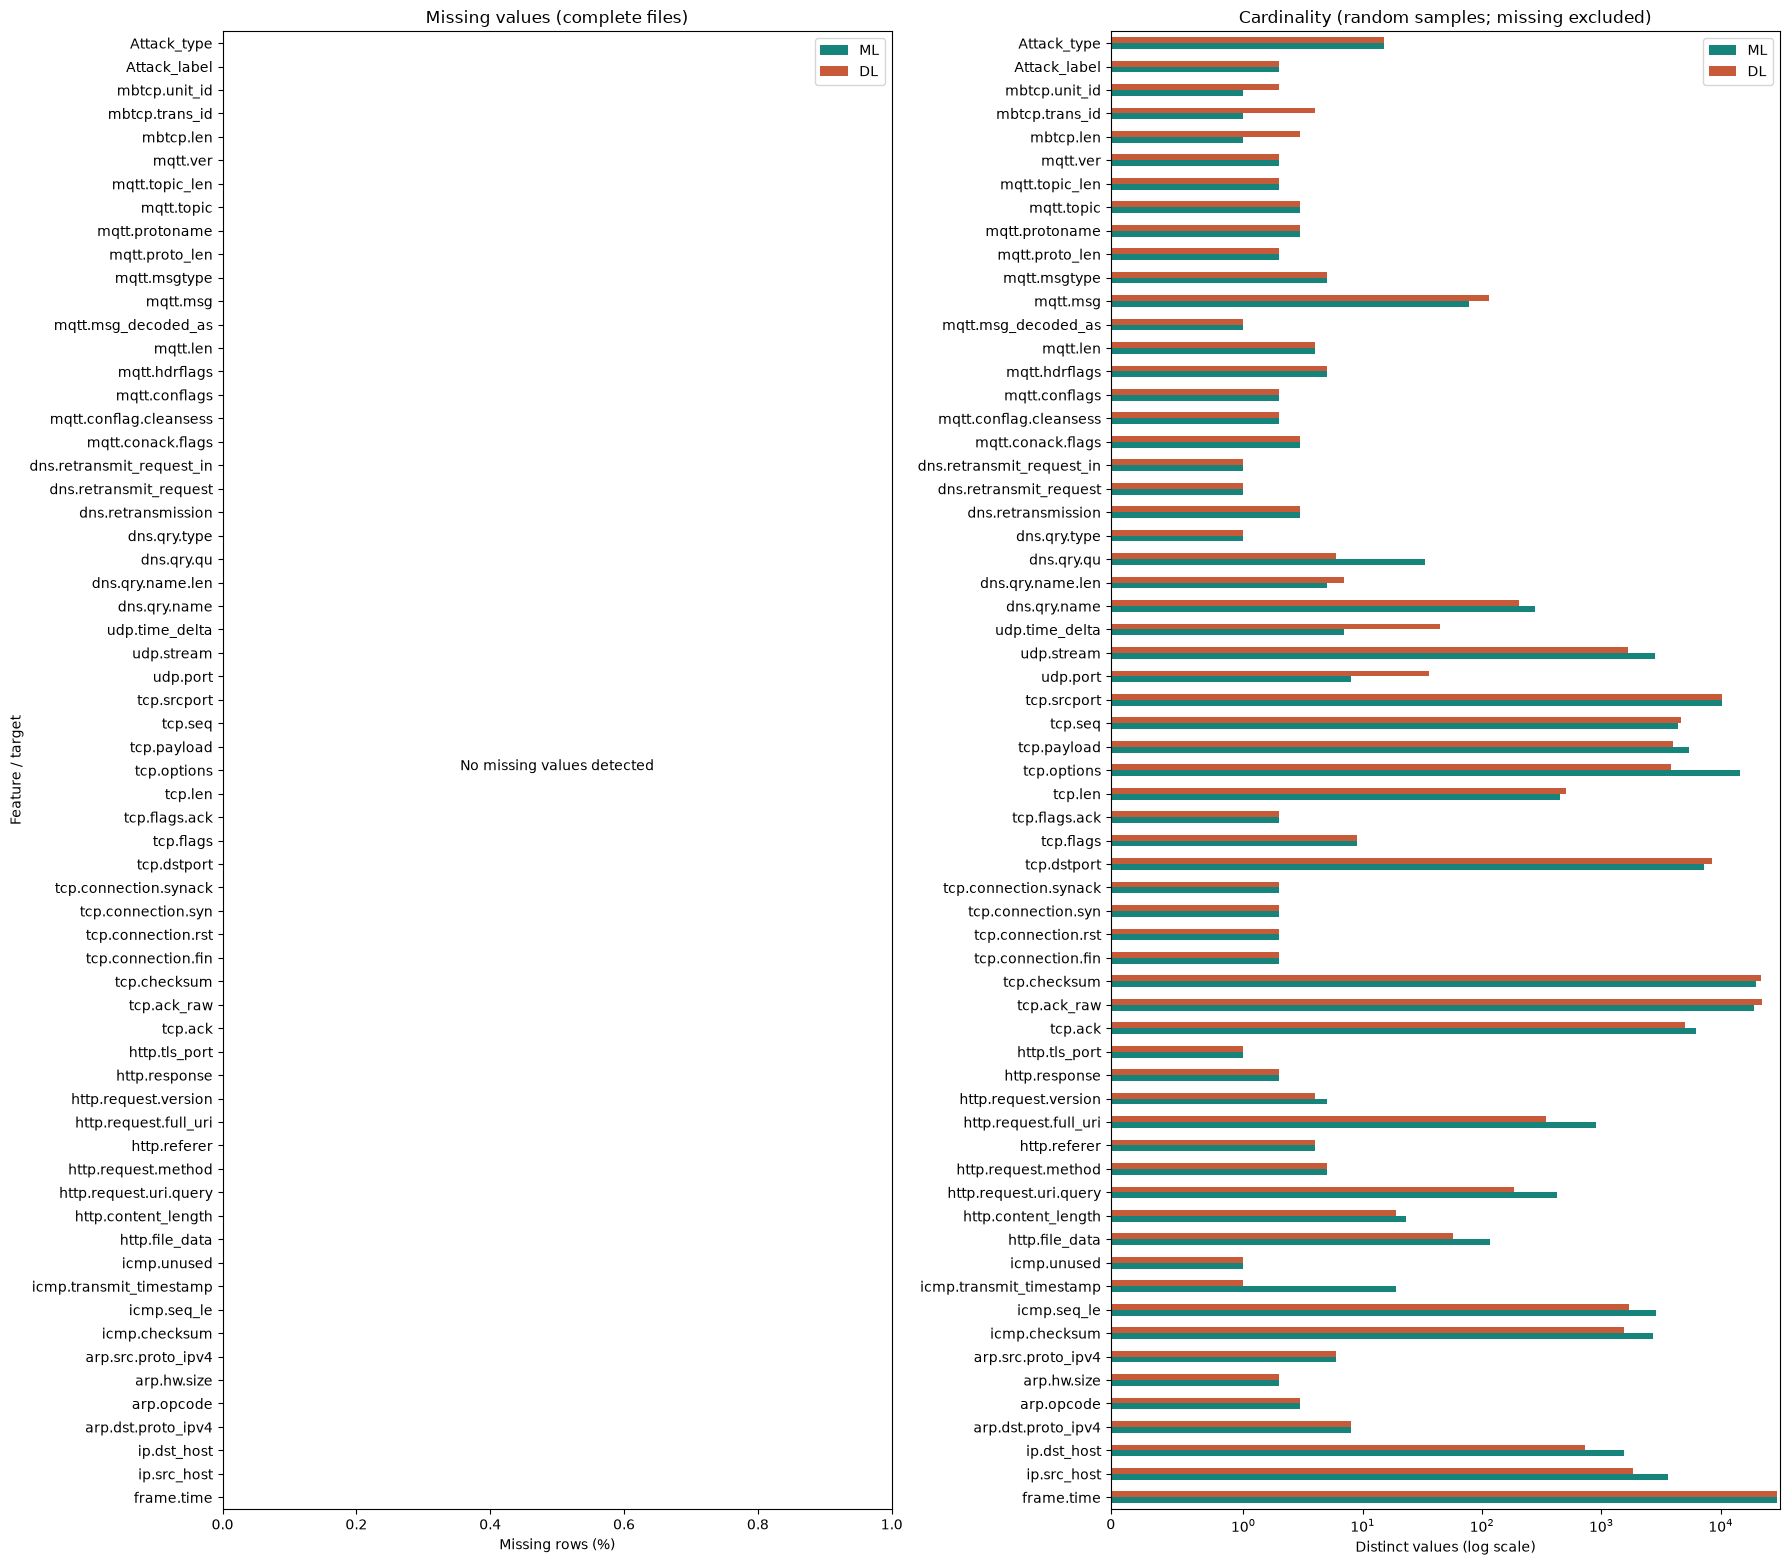

Attack_label: complete-file counts and percentages


count          percentage        
                  ML       DL         ML      DL
Attack_label                                    
0              24301  1615643       15.4  72.803
1             133499   603558       84.6  27.197

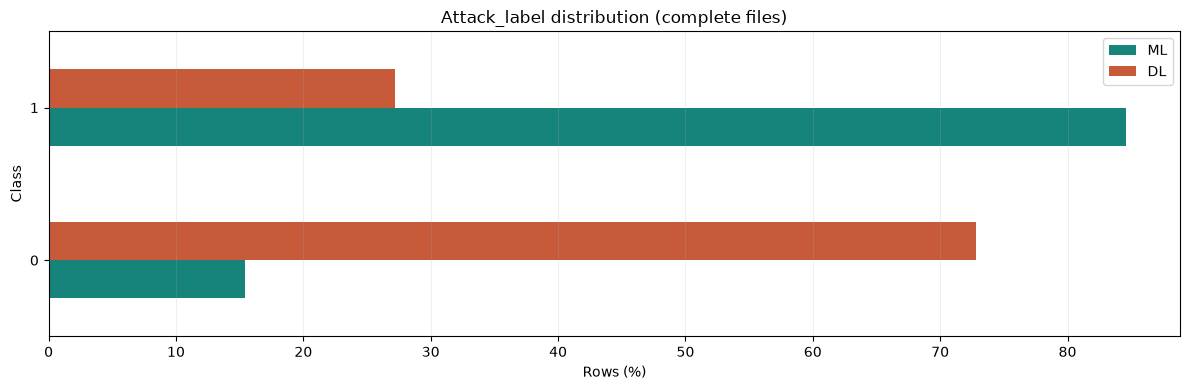

Attack_type: complete-file counts and percentages


count          percentage        
                          ML       DL         ML      DL
Attack_type                                             
Backdoor               10195    24862      6.461   1.120
DDoS_HTTP              10561    49911      6.693   2.249
DDoS_ICMP              14090   116436      8.929   5.247
DDoS_TCP               10247    50062      6.494   2.256
DDoS_UDP               14498   121568      9.188   5.478
Fingerprinting          1001     1001      0.634   0.045
MITM                    1214     1214      0.769   0.055
Normal                 24301  1615643     15.400  72.803
Password                9989    50153      6.330   2.260
Port_Scanning          10071    22564      6.382   1.017
Ransomware             10925    10925      6.923   0.492
SQL_injection          10311    51203      6.534   2.307
Uploading              10269    37634      6.508   1.696
Vulnerability_scanner  10076    50110      6.385   2.258
XSS                    10052    15915      6.370   0.717

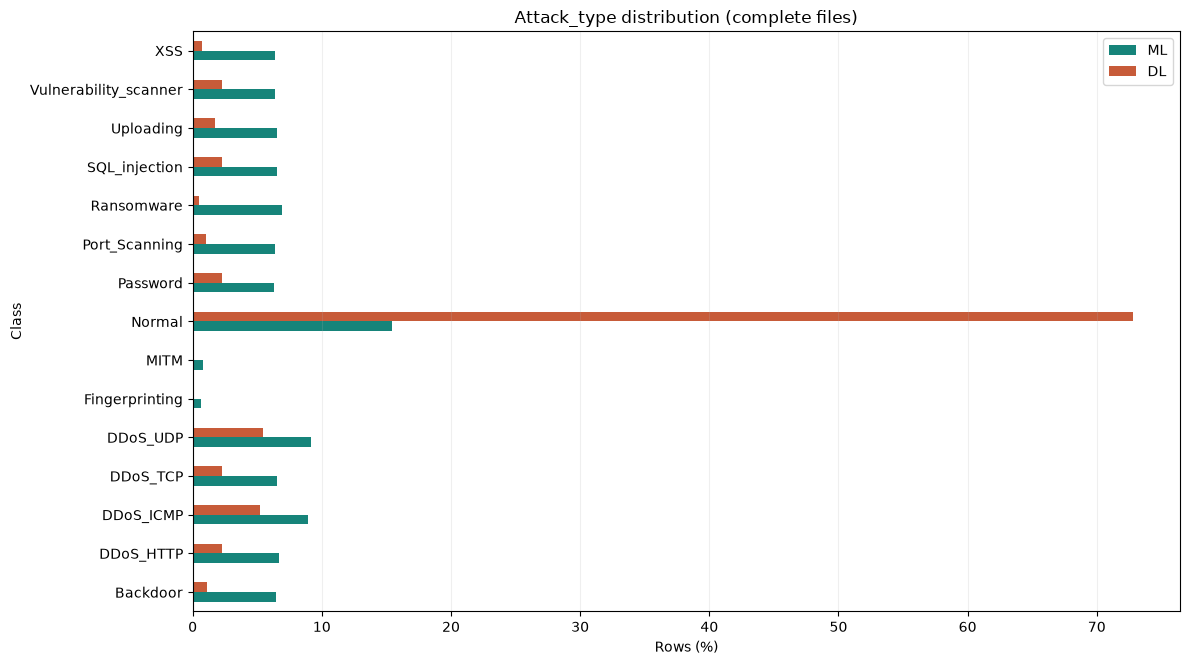

In [11]:
dataset_colors = {"ML": "#16847A", "DL": "#C75B39"}

missing_comparison = pd.concat(
    {dataset: result["profile"]["missing_pct_full"] for dataset, result in eda_results.items()},
    axis=1,
).fillna(0)
cardinality_comparison = pd.concat(
    {dataset: result["profile"]["unique_sample"] for dataset, result in eda_results.items()},
    axis=1,
)

fig, axes = plt.subplots(1, 2, figsize=(18, max(8, len(missing_comparison) * 0.25)))
missing_comparison.plot.barh(ax=axes[0], color=list(dataset_colors.values()))
axes[0].set(title="Missing values (complete files)", xlabel="Missing rows (%)", ylabel="Feature / target")
axes[0].set_xlim(0, max(1, missing_comparison.max().max() * 1.15))
if not missing_comparison.to_numpy().any():
    axes[0].text(0.5, 0.5, "No missing values detected", transform=axes[0].transAxes, ha="center")
cardinality_comparison.plot.barh(ax=axes[1], color=list(dataset_colors.values()))
axes[1].set(title="Cardinality (random samples; missing excluded)", xlabel="Distinct values (log scale)", ylabel="")
axes[1].set_xscale("symlog", linthresh=1)
fig.tight_layout()
plt.show()

for target in TARGET_COLUMNS:
    counts = pd.concat(
        {dataset: result["classes"][target] for dataset, result in eda_results.items() if target in result["classes"]},
        axis=1,
    ).fillna(0).astype("int64")
    percentages = counts.div(dataset_overview["rows_full"], axis="columns") * 100
    print(f"{target}: complete-file counts and percentages")
    display(pd.concat({"count": counts, "percentage": percentages.round(3)}, axis=1))
    fig, axis = plt.subplots(figsize=(12, max(4, len(counts) * 0.45)))
    percentages.plot.barh(ax=axis, color=list(dataset_colors.values()))
    axis.set(title=f"{target} distribution (complete files)", xlabel="Rows (%)", ylabel="Class")
    axis.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    plt.show()

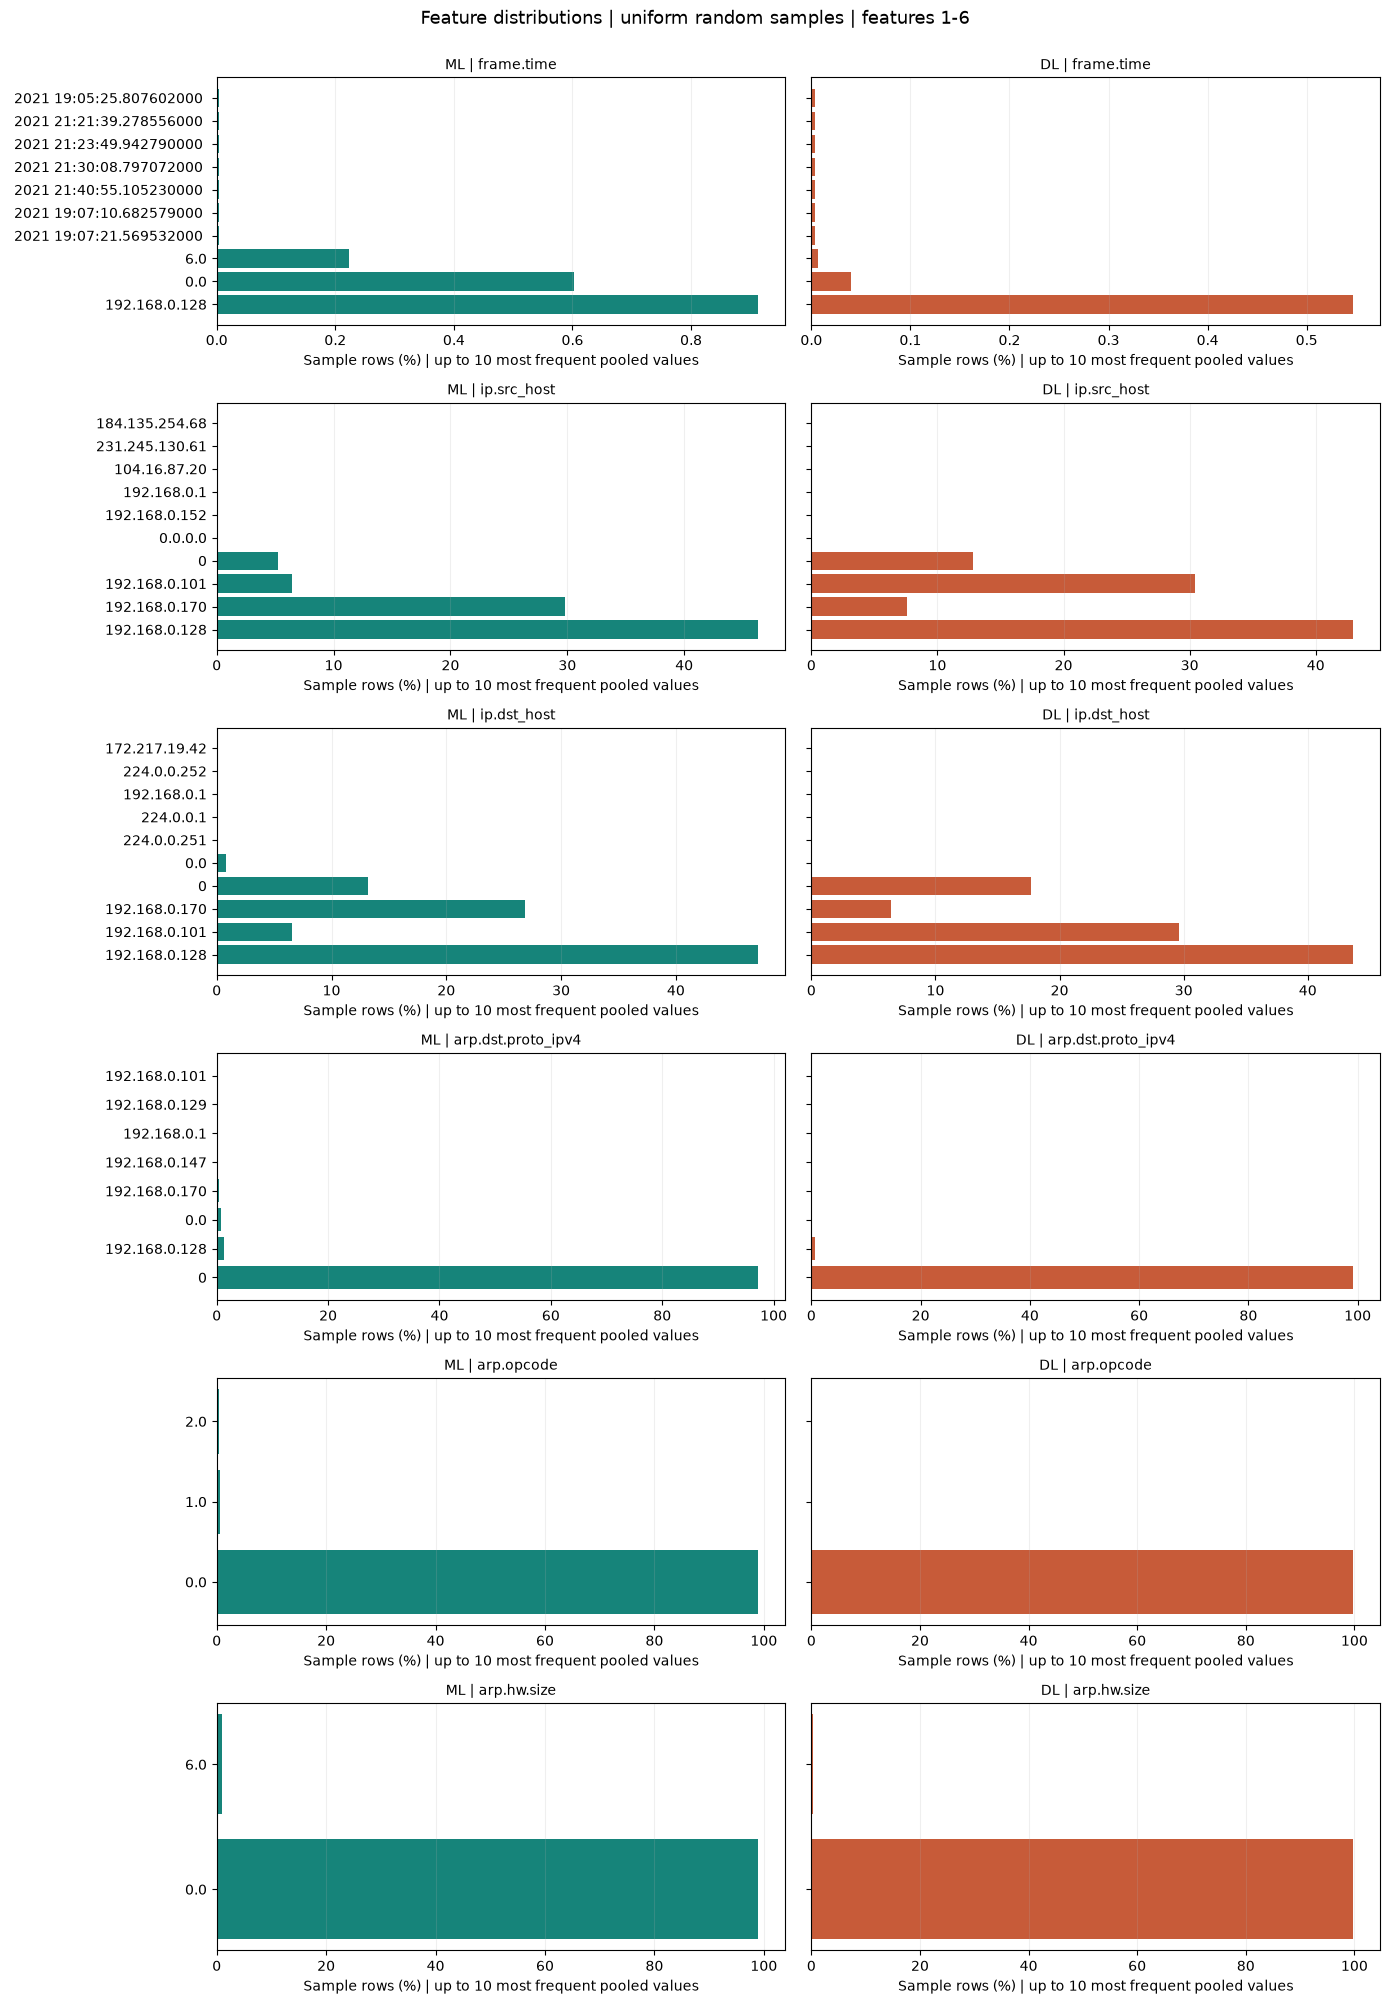

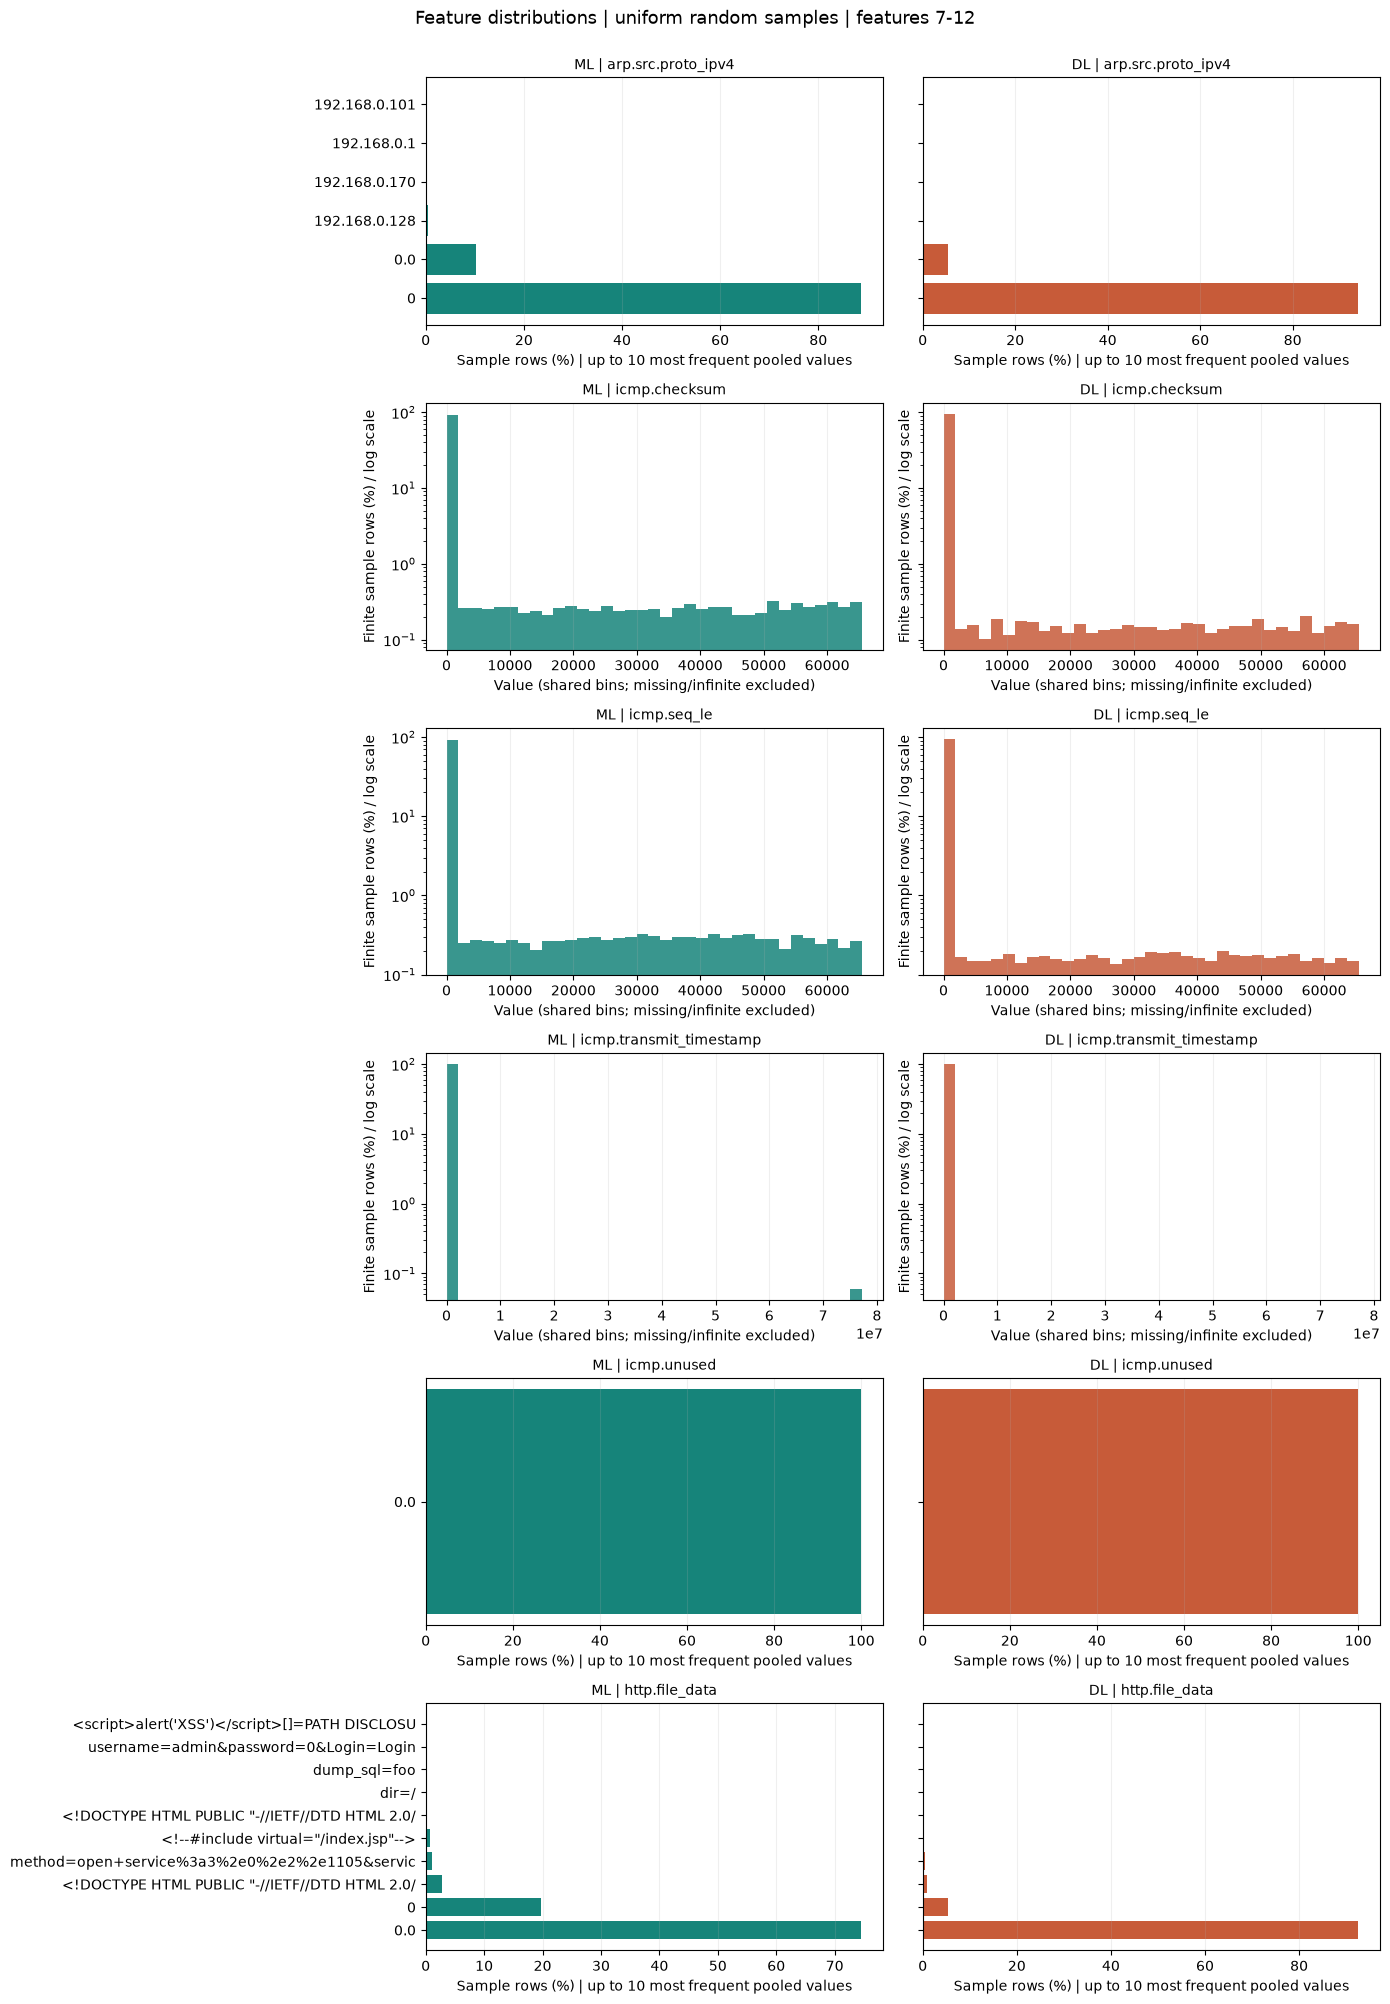

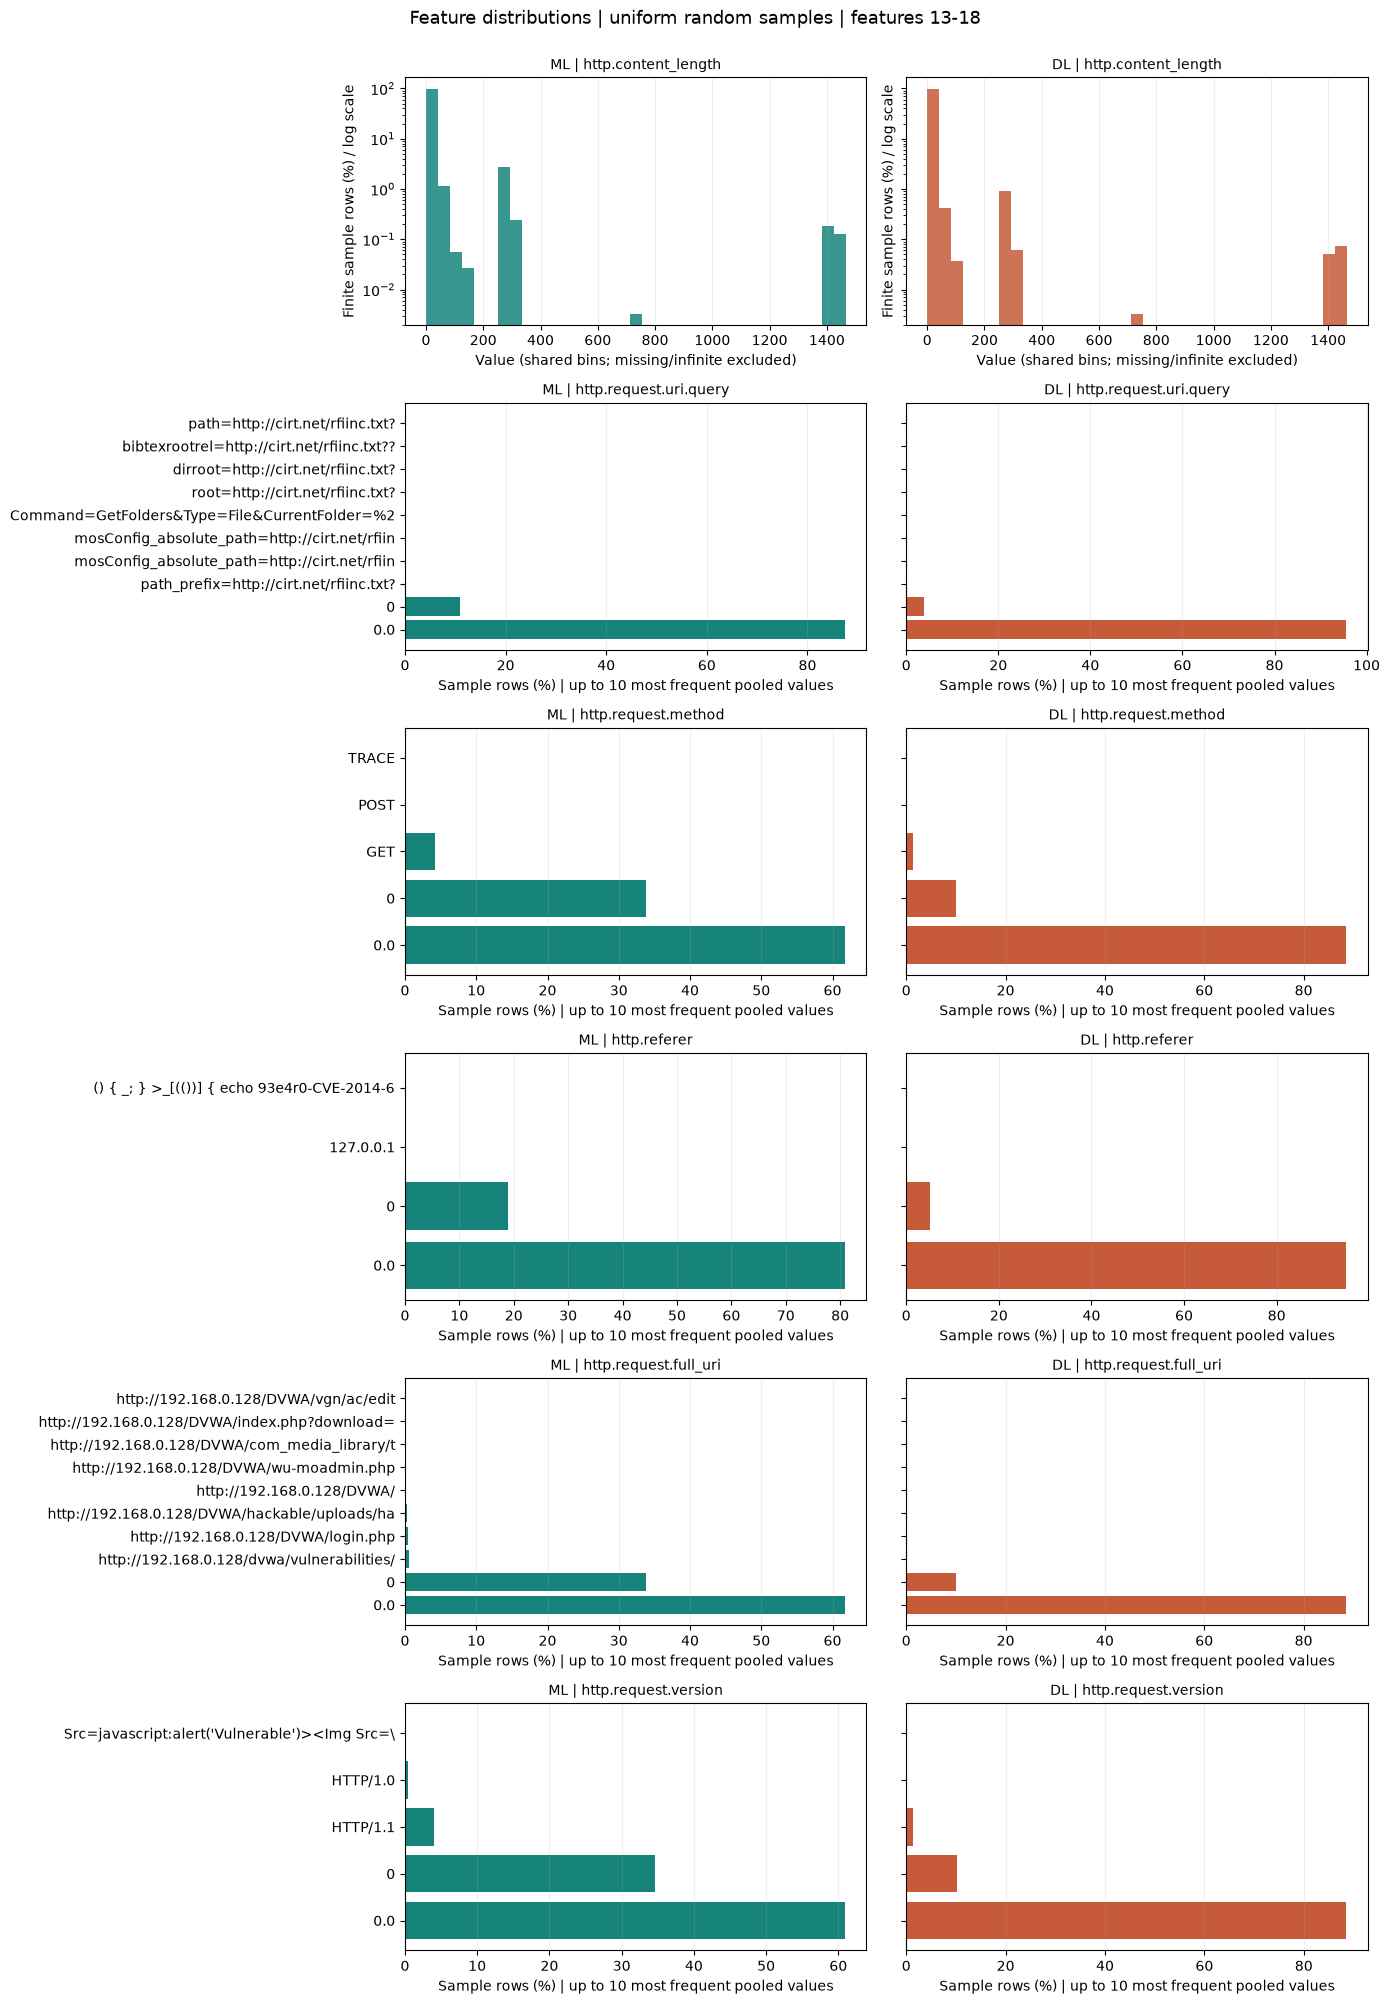

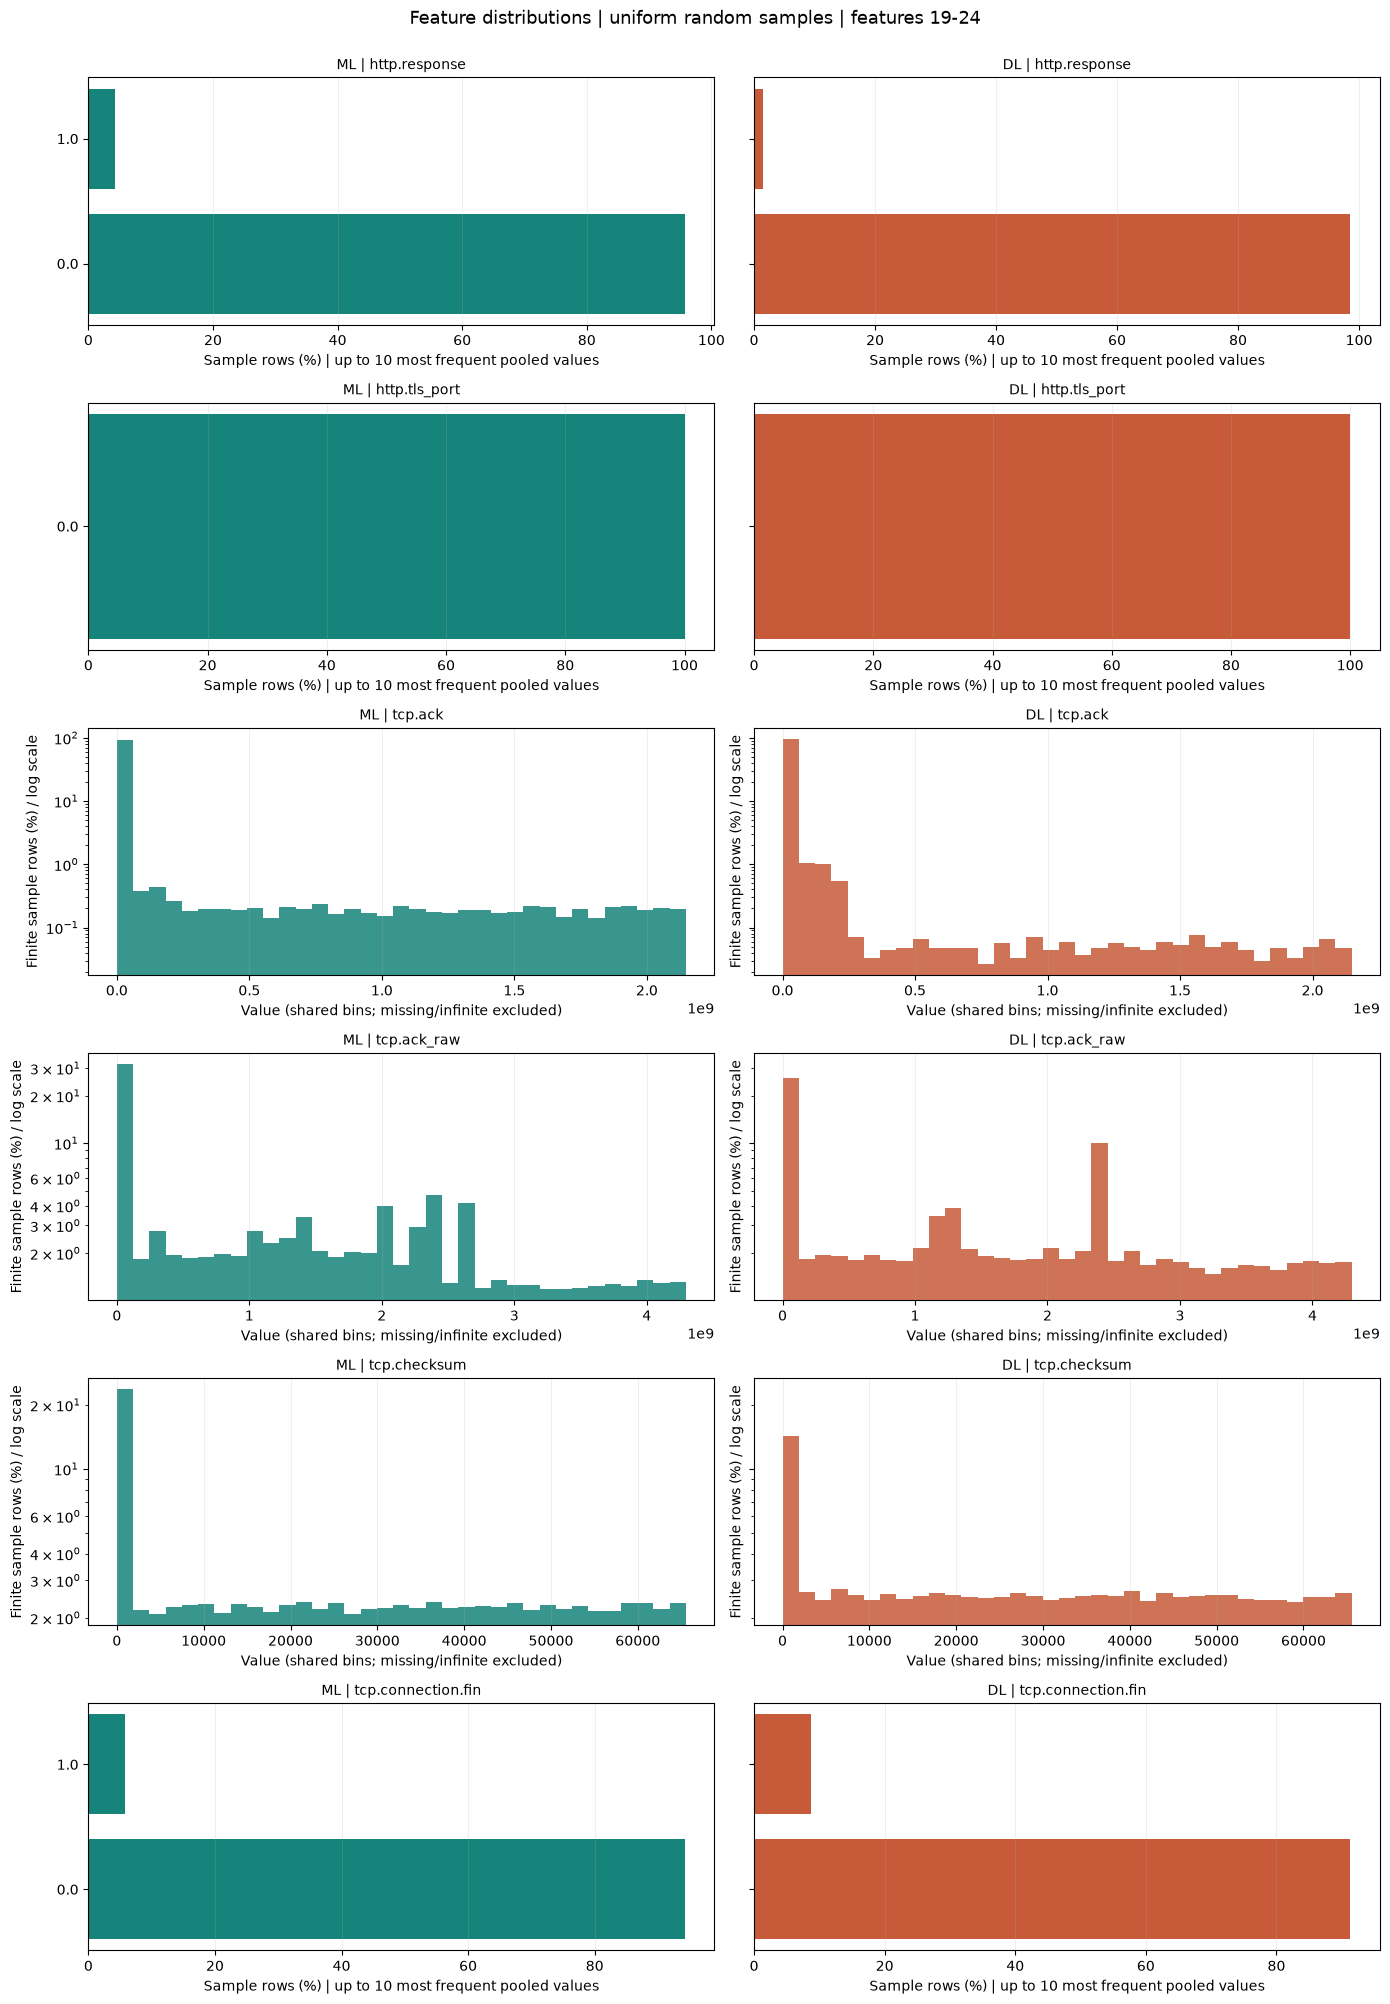

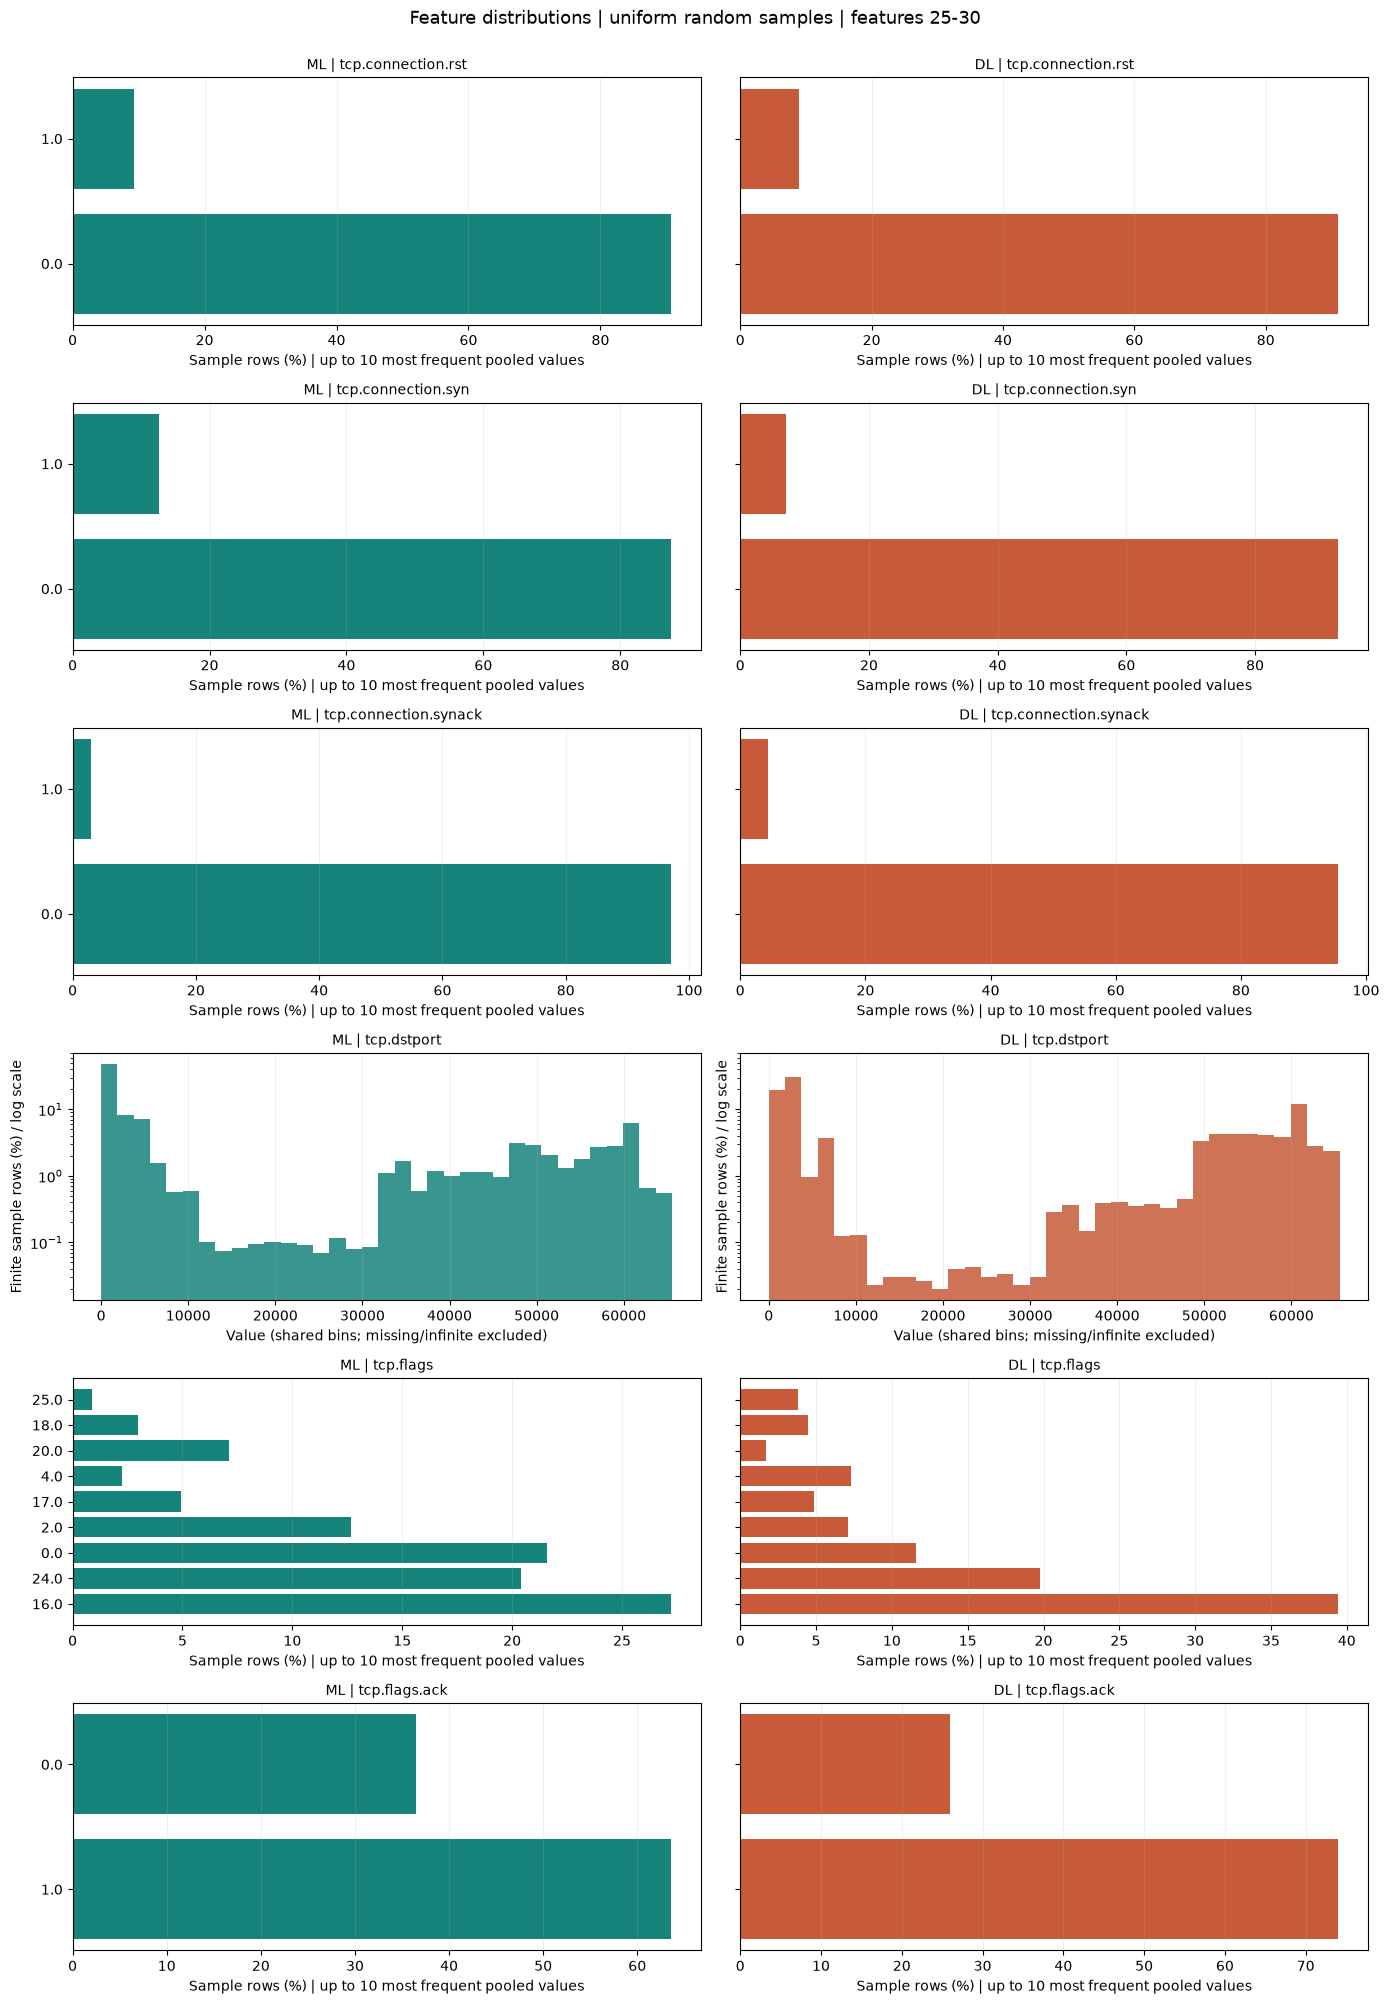

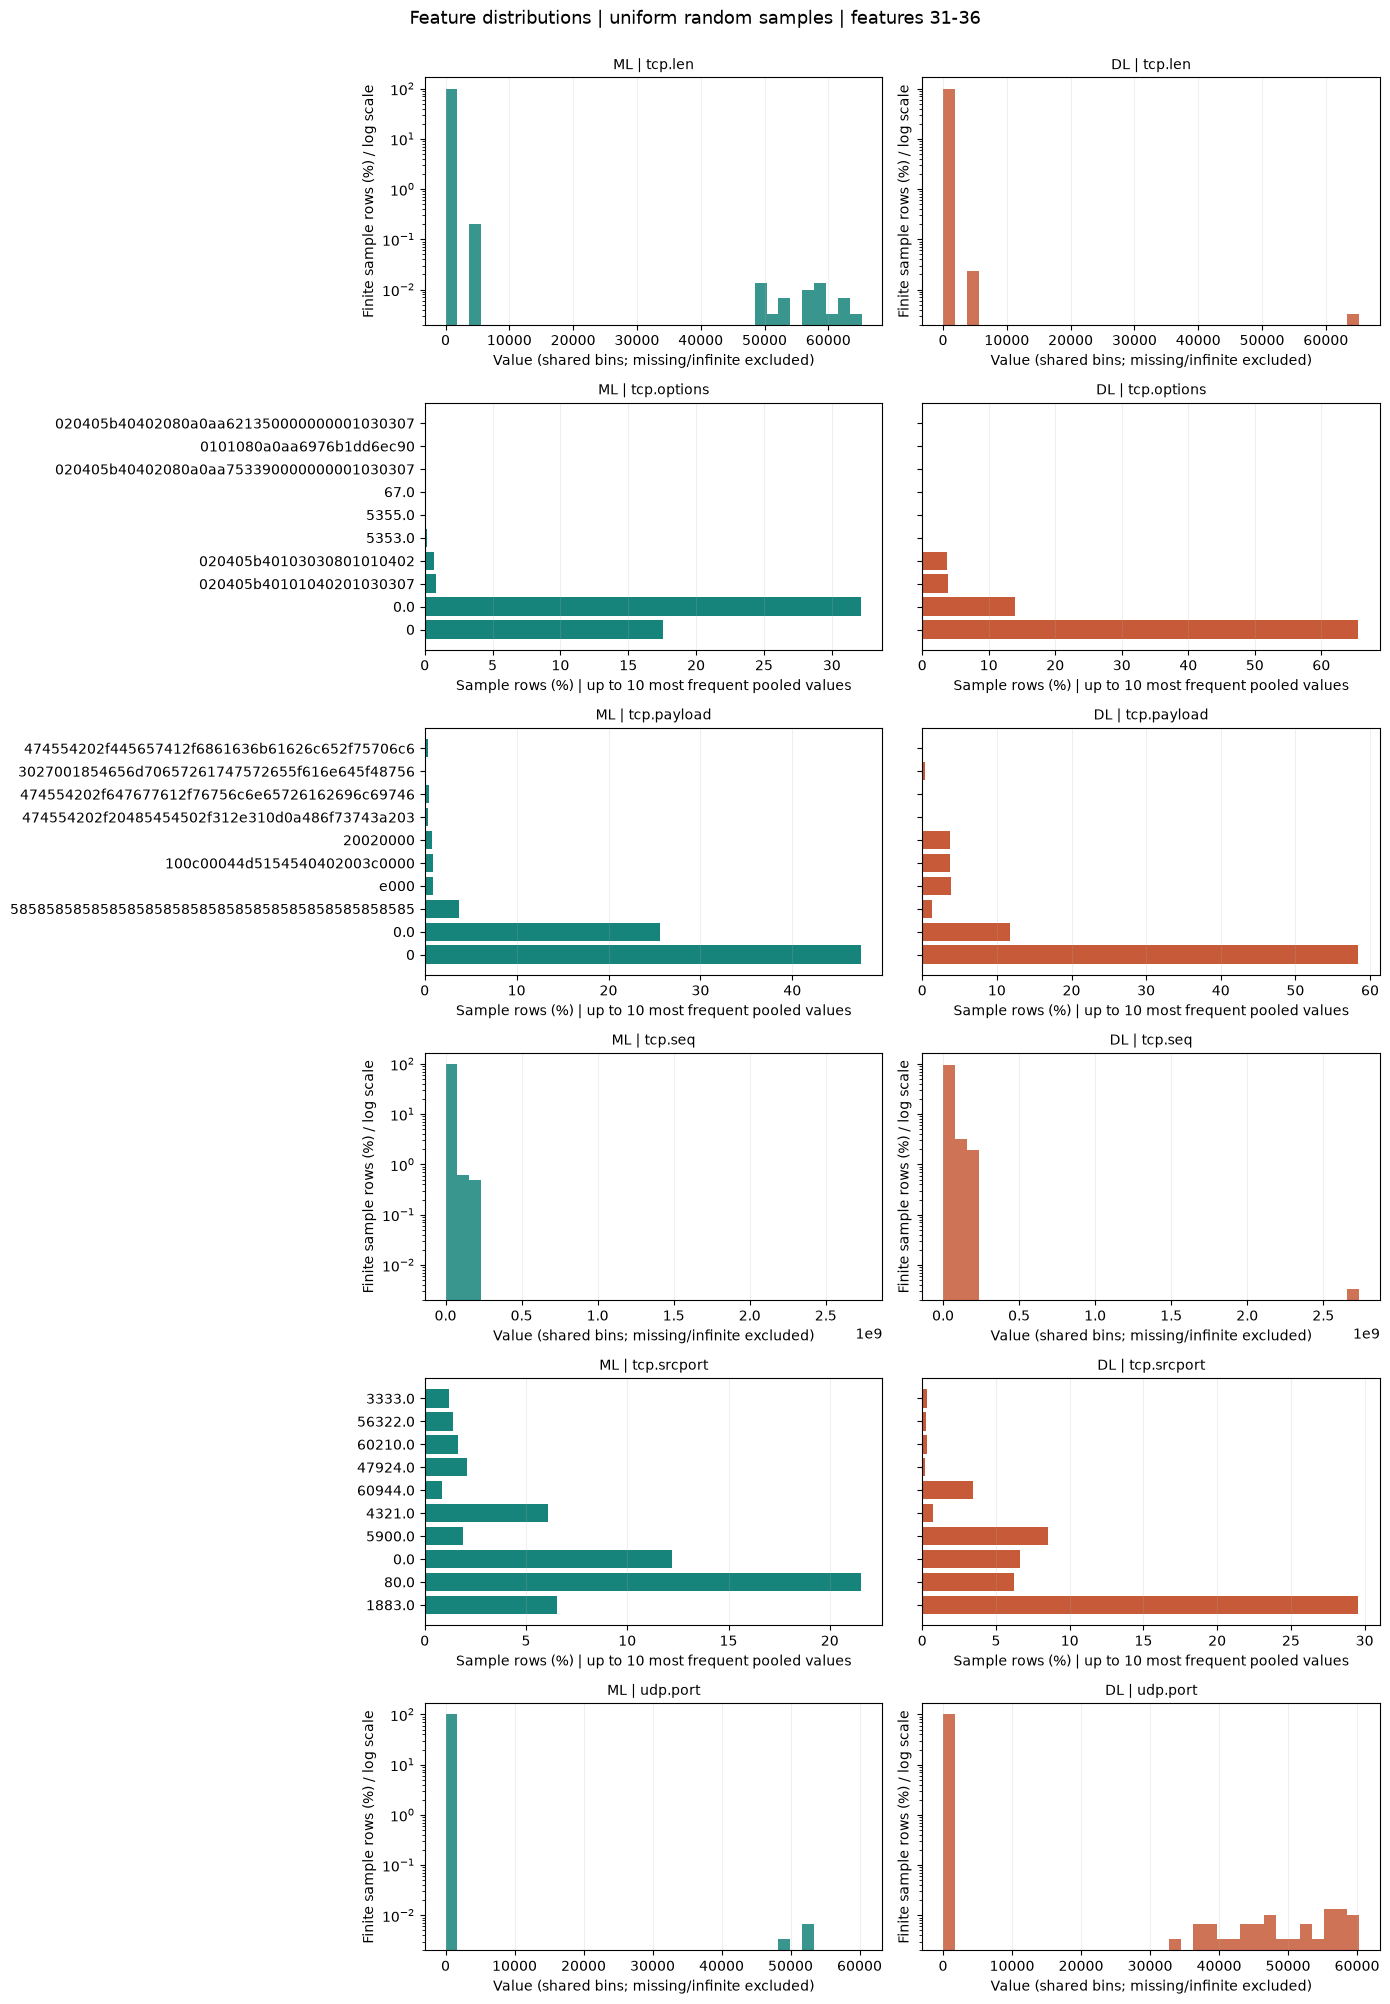

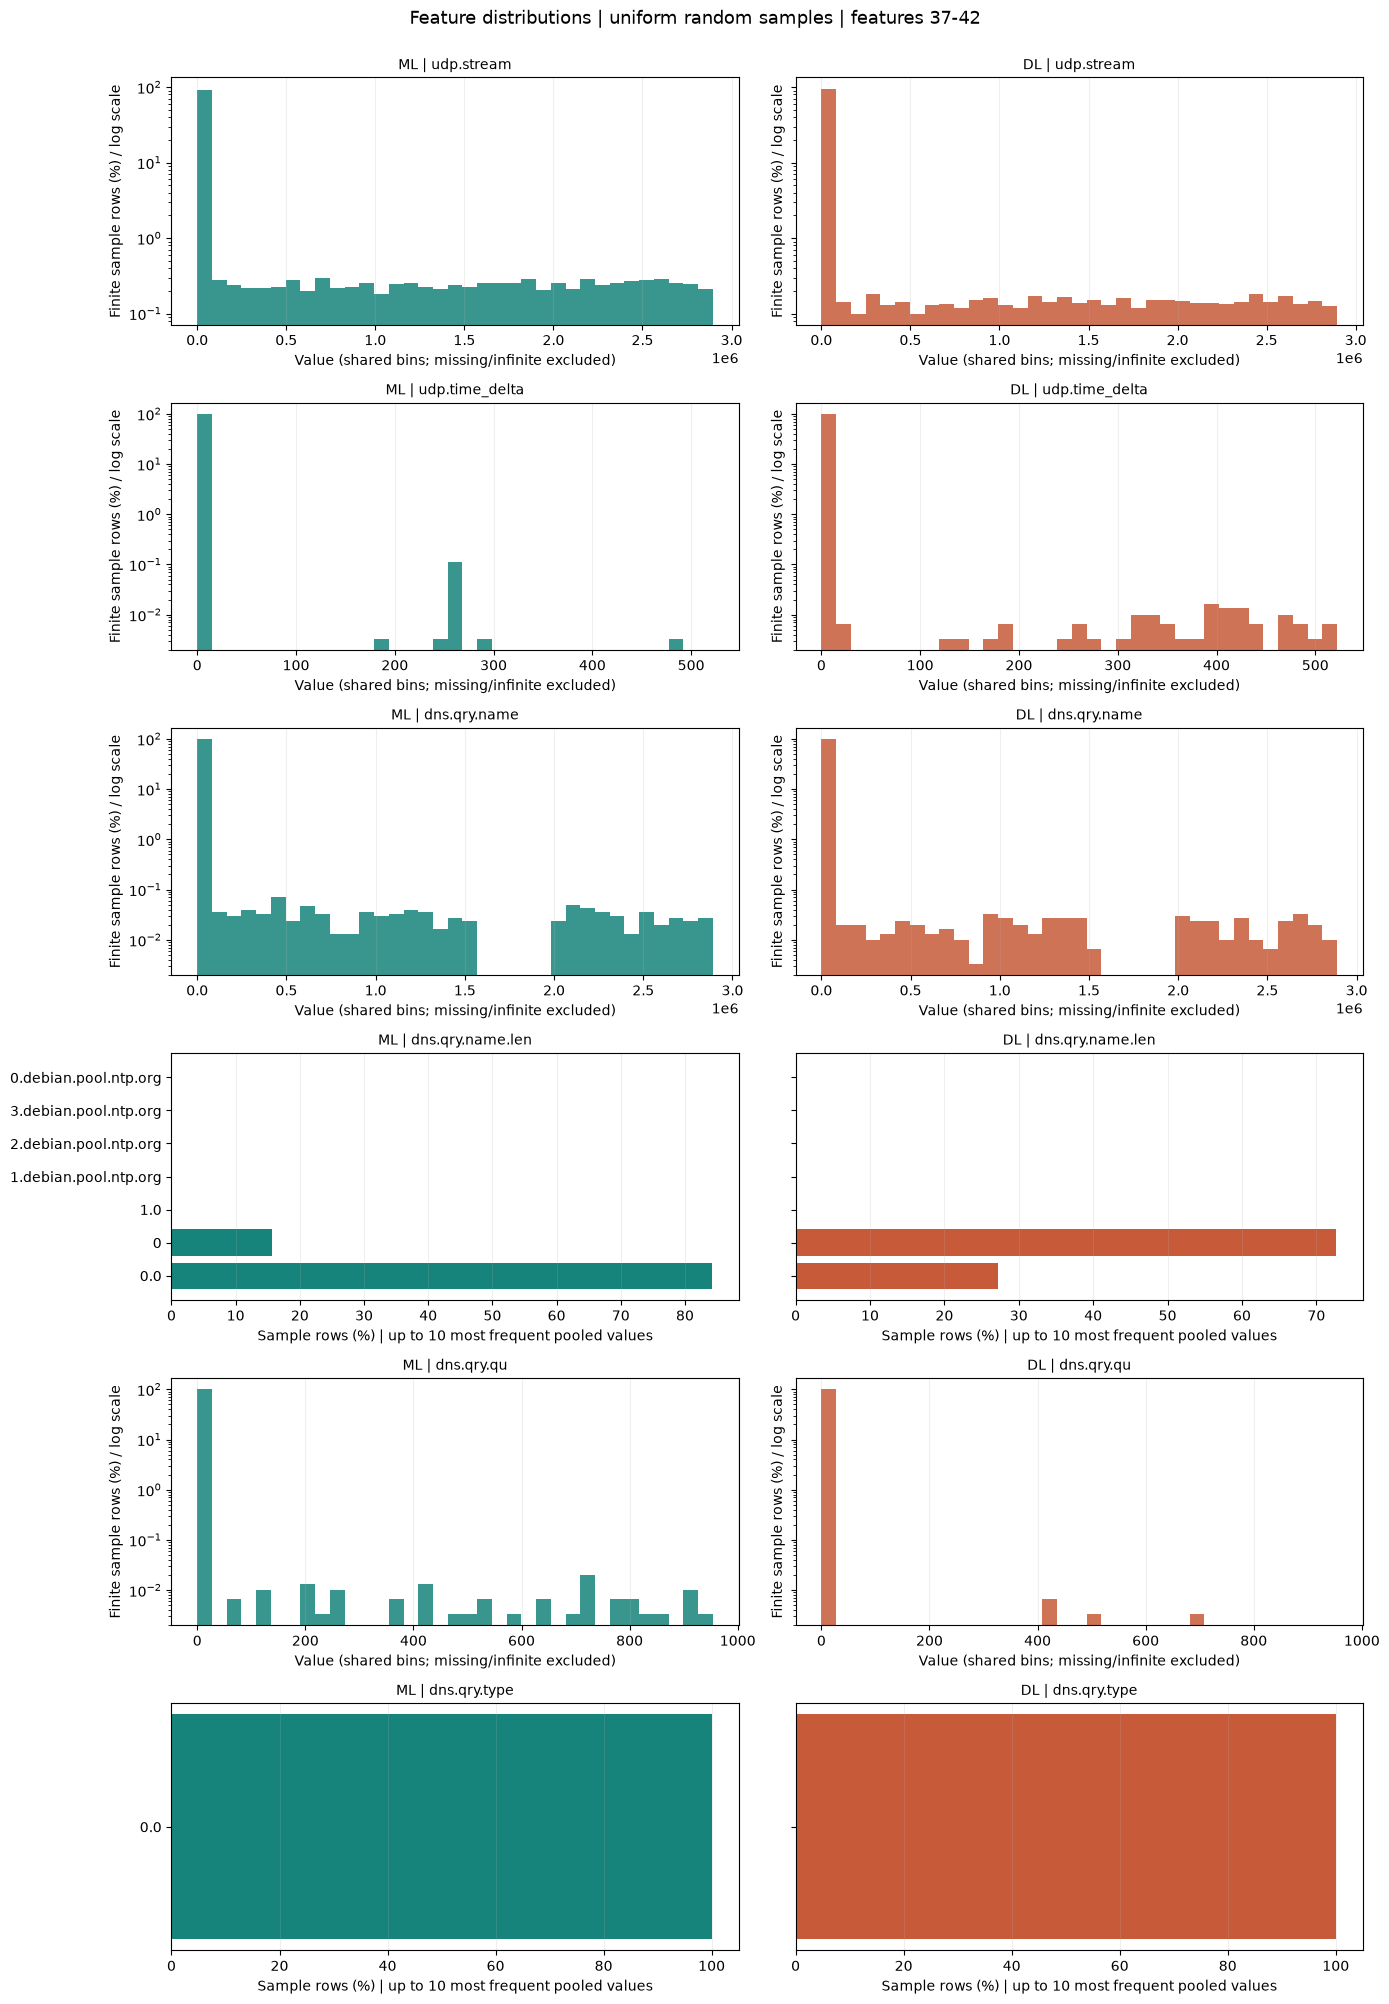

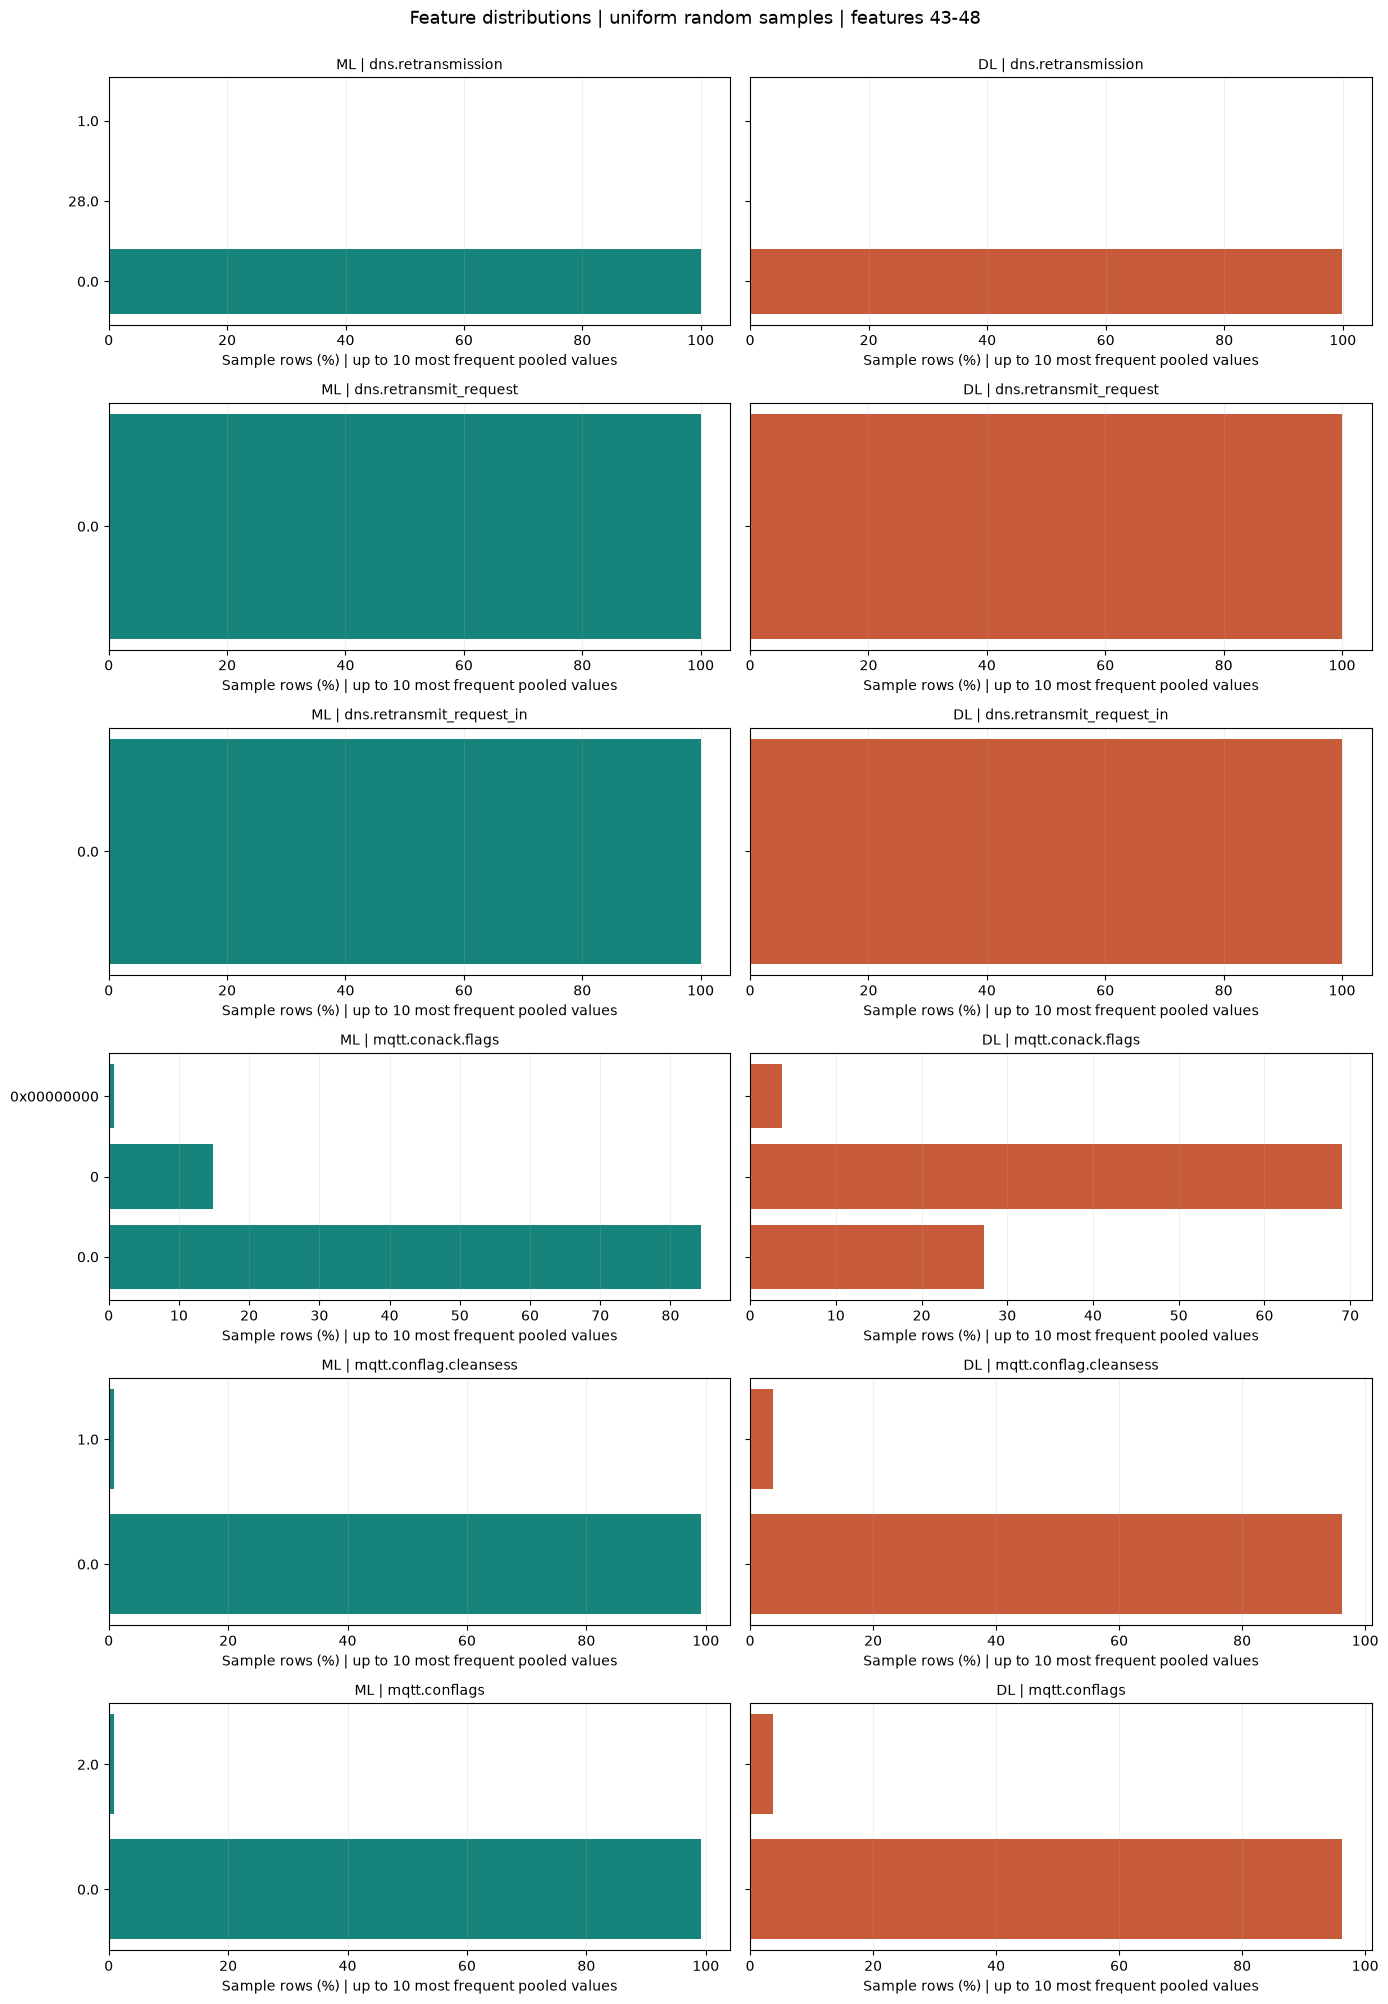

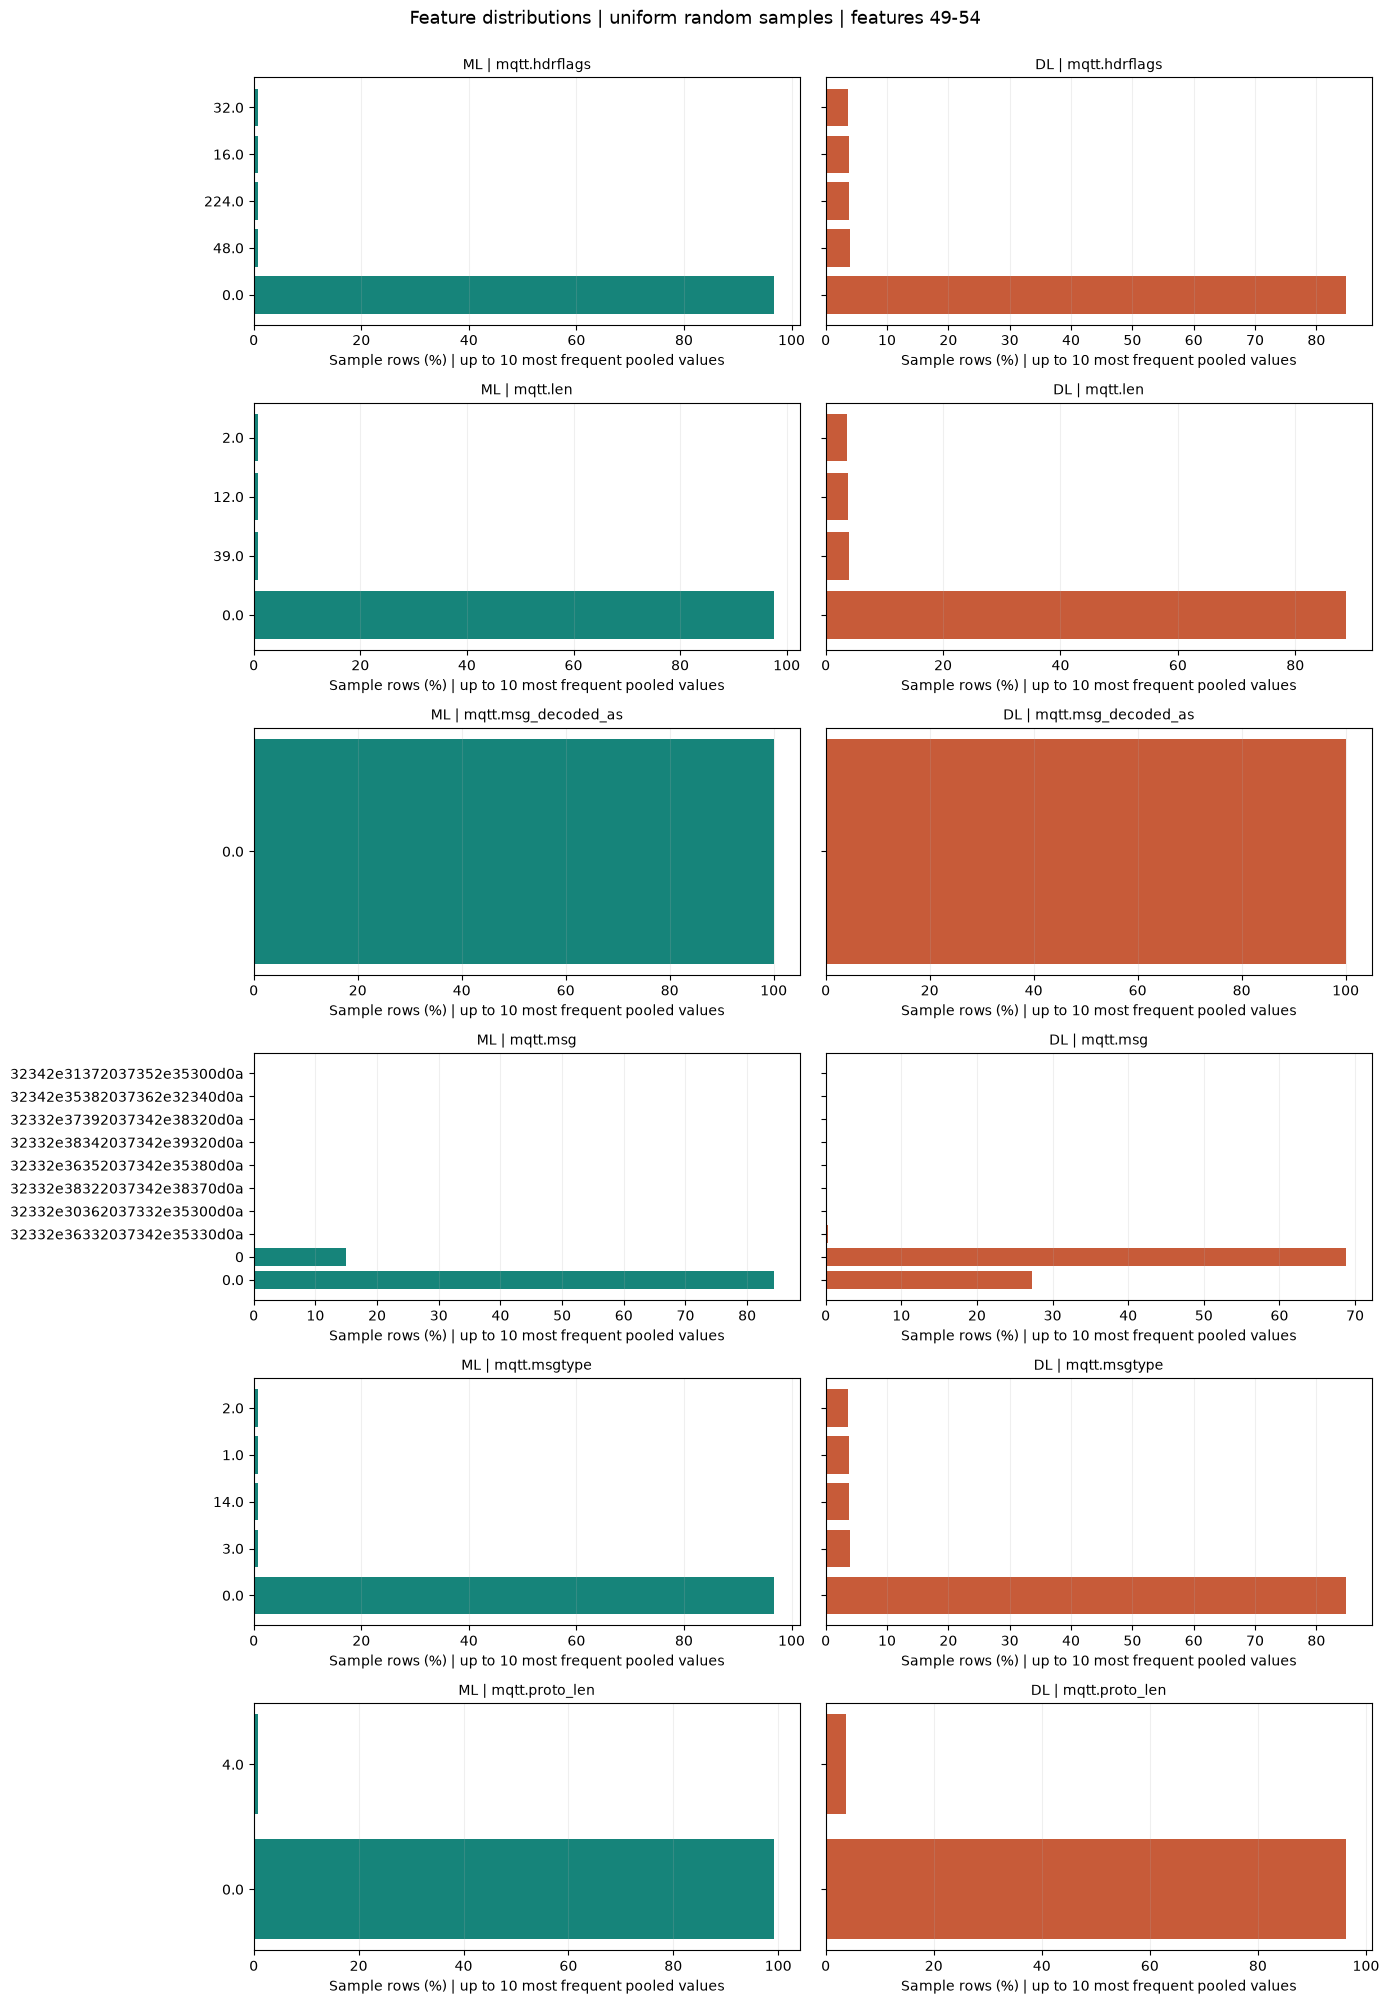

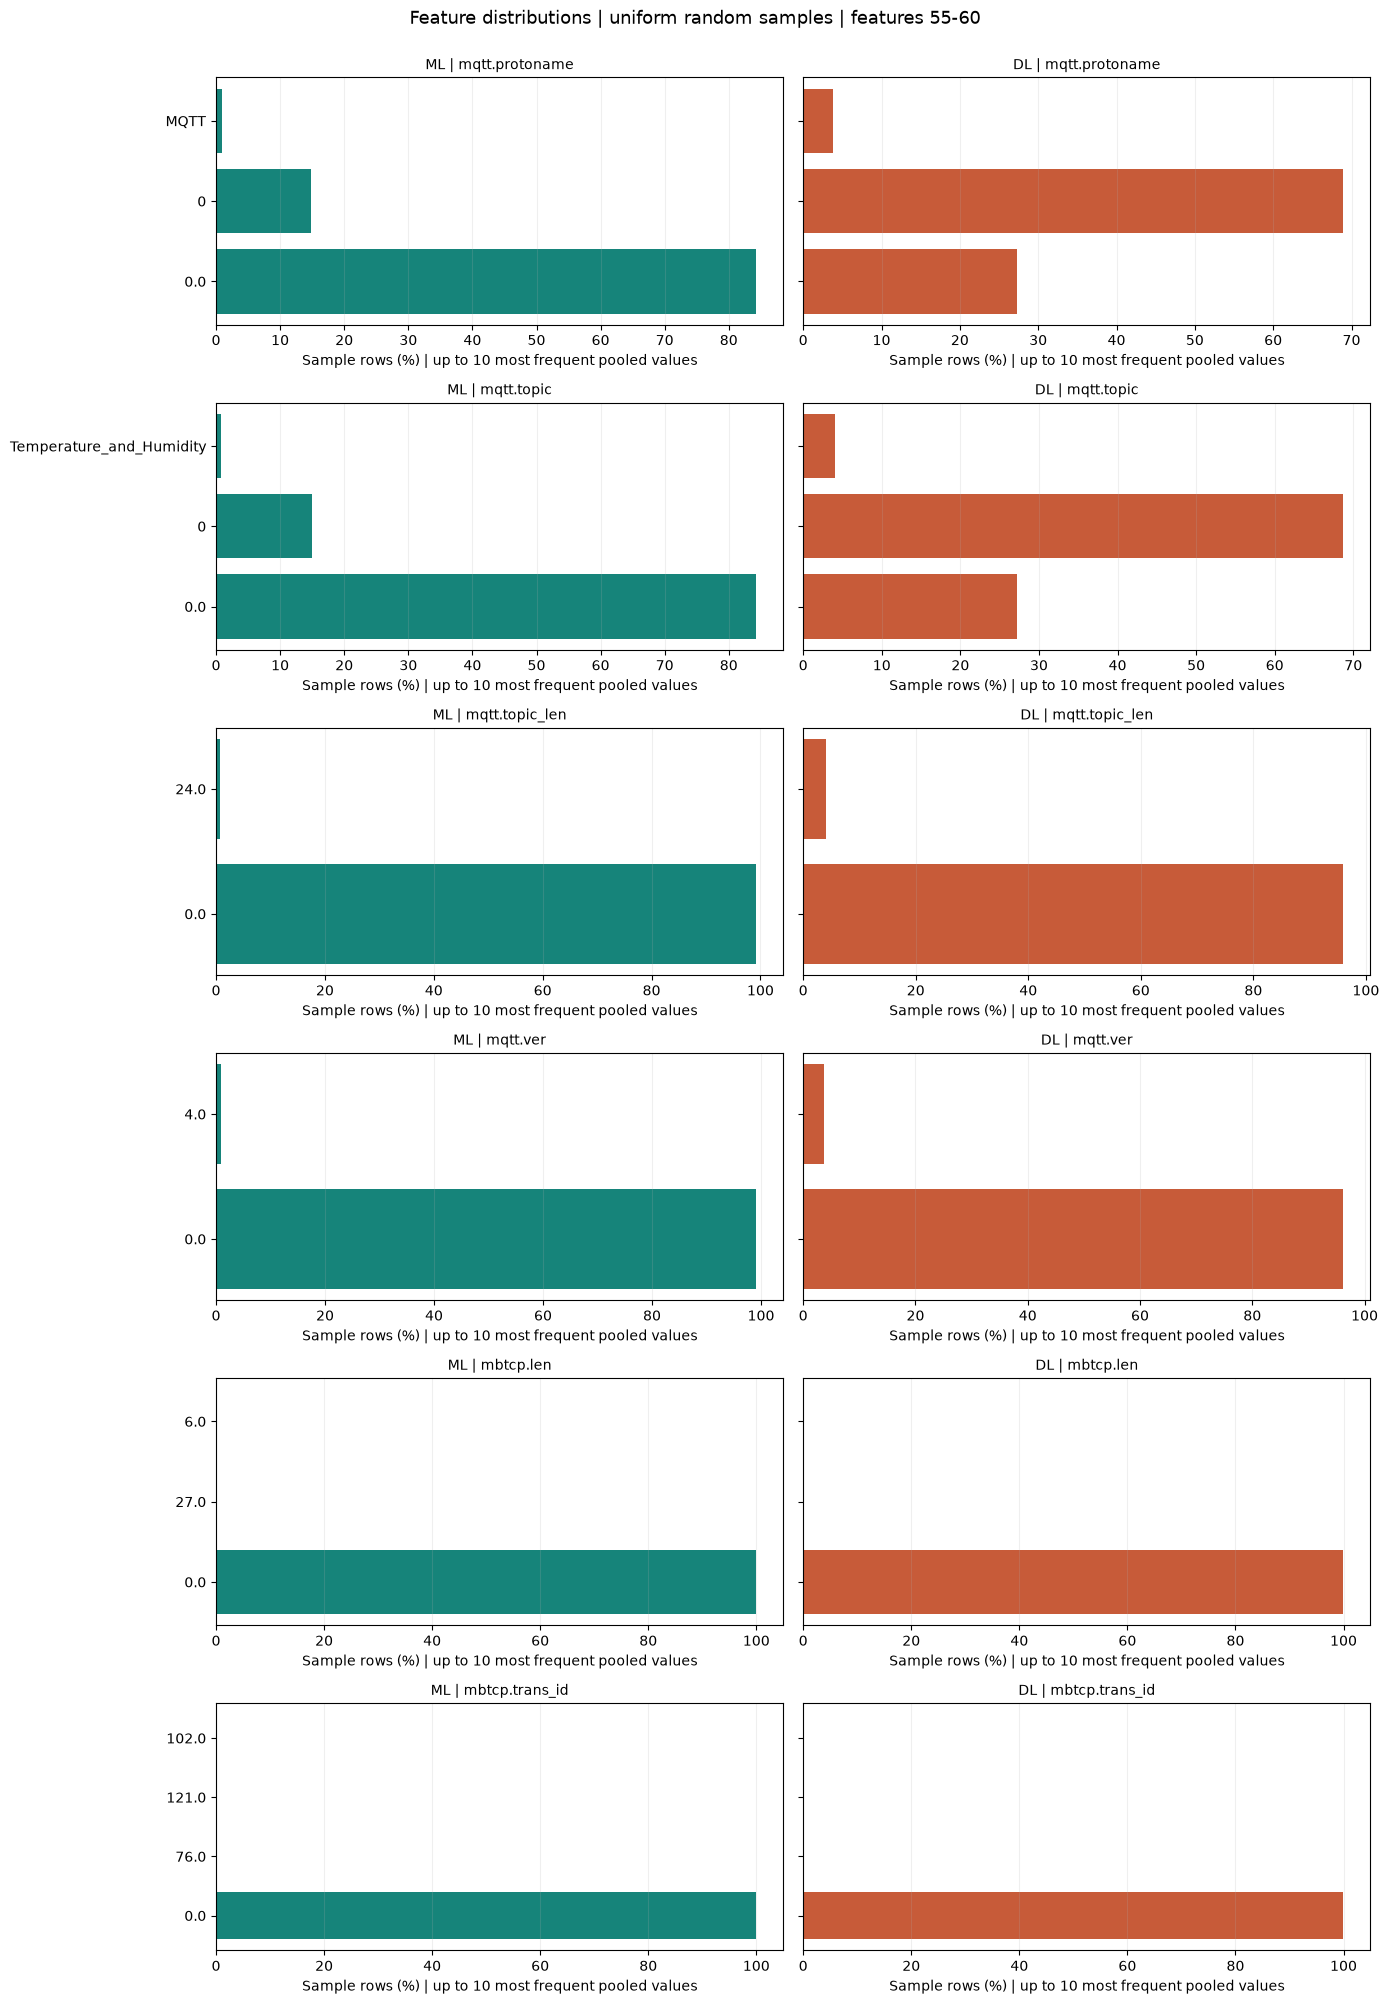

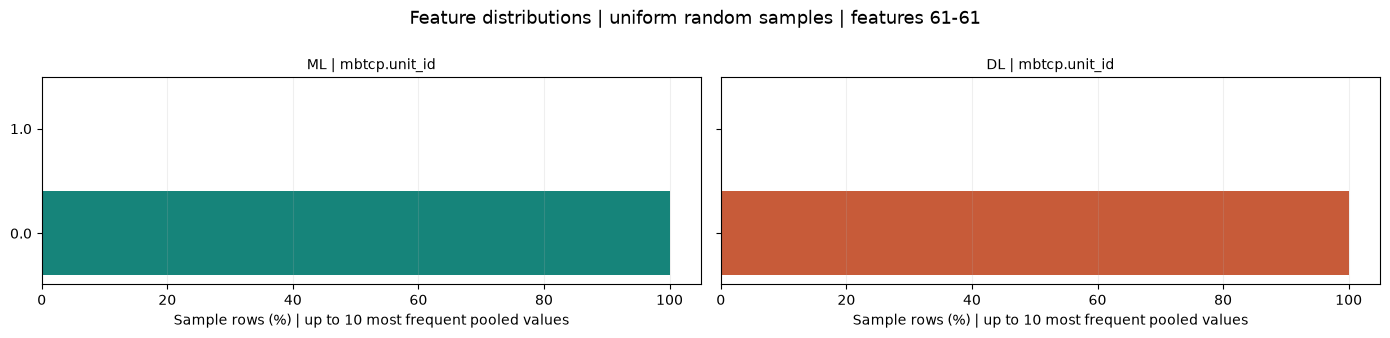

In [13]:
FEATURES_PER_FIGURE = 6
HISTOGRAM_BINS = 35
TOP_CATEGORIES = 10

features = list(dict.fromkeys(
    feature
    for result in eda_results.values()
    for feature in result["sample"].columns
    if feature not in TARGET_COLUMNS
))

for start in range(0, len(features), FEATURES_PER_FIGURE):
    page_features = features[start:start + FEATURES_PER_FIGURE]
    fig, axes = plt.subplots(
        len(page_features), 2, figsize=(14, 3.4 * len(page_features)),
        squeeze=False, sharey="row",
    )
    for row_index, feature in enumerate(page_features):
        series = {dataset: result["sample"][feature] for dataset, result in eda_results.items() if feature in result["sample"]}
        numeric_feature = all(
            eda_results[dataset]["profile"].loc[feature, "type_in_sample"] == "numeric"
            for dataset in series
        )
        numeric_values = {
            dataset: pd.to_numeric(values, errors="coerce").astype("float64")
            for dataset, values in series.items()
        } if numeric_feature else {}
        finite_values = {
            dataset: values[np.isfinite(values)] for dataset, values in numeric_values.items()
        }
        combined = pd.concat(list(series.values()), ignore_index=True)
        use_histogram = numeric_feature and combined.nunique() > TOP_CATEGORIES
        if use_histogram:
            combined_finite = pd.concat(list(finite_values.values()), ignore_index=True)
            bins = np.histogram_bin_edges(combined_finite.to_numpy(), bins=HISTOGRAM_BINS) if len(combined_finite) else None
        else:
            categories = combined.fillna("<MISSING>").value_counts().head(TOP_CATEGORIES).index

        for column_index, dataset in enumerate(dataset_names):
            axis = axes[row_index, column_index]
            axis.set_title(f"{dataset} | {feature}", fontsize=10)
            if dataset not in series:
                axis.text(0.5, 0.5, "Feature not available", ha="center", transform=axis.transAxes)
                continue
            if use_histogram:
                values = finite_values[dataset]
                if len(values) and bins is not None:
                    axis.hist(
                        values.to_numpy(), bins=bins,
                        weights=np.full(len(values), 100 / len(values)),
                        color=dataset_colors[dataset], alpha=0.85,
                    )
                    axis.set_yscale("log")
                else:
                    axis.text(0.5, 0.5, "No finite numeric values", ha="center", transform=axis.transAxes)
                axis.set_xlabel("Value (shared bins; missing/infinite excluded)")
                axis.set_ylabel("Finite sample rows (%) / log scale")
            else:
                percentages = series[dataset].fillna("<MISSING>").value_counts(normalize=True).reindex(categories, fill_value=0) * 100
                axis.barh(np.arange(len(categories)), percentages.to_numpy(), color=dataset_colors[dataset])
                axis.set_yticks(np.arange(len(categories)), [str(value)[:45] for value in categories])
                axis.set_xlabel("Sample rows (%) | up to 10 most frequent pooled values")
            axis.grid(axis="x", alpha=0.2)

    fig.suptitle(
        f"Feature distributions | uniform random samples | features {start + 1}-{start + len(page_features)}",
        fontsize=13,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()